# Reproducing Le, Abel and Laforge (2026) on OULAD



In [1]:
import logging
import subprocess
import sys
import tempfile
import time
import warnings
from collections import Counter
from pathlib import Path
from types import SimpleNamespace

import pandas as pd
from IPython.display import Image, Markdown, display

candidates = [Path.cwd(), Path.cwd() / "leap-early-prediction"]
REPO = next((path for path in candidates if (path / "train_eval.py").exists()), None)
assert REPO is not None, f"Could not find the authors' code from {Path.cwd()}"
DATA_DIR = REPO.parent / "Oulab"
sys.path.insert(0, str(REPO))

from config import DEFAULT_SEEDS, display_model_name
from data_load import load_oulad_data
from main import _normalize_models
from train_eval import run_benchmark

logging.basicConfig(level=logging.WARNING, format="%(levelname)s | %(message)s")
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
pd.options.display.float_format = "{:.4f}".format

TOLERANCE = 0.01


def signed(value):
    return f"{value:+.4f}"


print("Authors' code:", REPO)
print("Data folder:  ", DATA_DIR)

Authors' code: /Users/user/Desktop/FYI/leap-early-prediction
Data folder:   /Users/user/Desktop/FYI/Oulab


## 1. Environment

Confirms the notebook is running in `fyp` and lists every installed package.

In [2]:
in_fyp = Path(sys.prefix).name == "fyp"
print("Python:", sys.version.split()[0])
print("Interpreter:", sys.executable)
print("Running in fyp:", in_fyp)
assert in_fyp, "Select the fyp kernel, then run this notebook again."

freeze = subprocess.run(
    [sys.executable, "-m", "pip", "freeze"], capture_output=True, text=True, check=True
).stdout
print(f"\nInstalled packages:\n\n{freeze}")

Python: 3.12.16
Interpreter: /opt/miniconda3/envs/fyp/bin/python
Running in fyp: True



Installed packages:

appnope==1.0.0
asttokens==3.0.2
attrs==26.1.0
cloudpickle==3.1.2
comm==0.2.3
contourpy==1.4.0
cycler==0.12.1
debugpy==1.8.22
executing==2.3.0
fastjsonschema==2.22.3
fonttools==4.68.0
ipykernel==7.4.0
ipython==9.18.1
ipython_pygments_lexers==1.1.1
jedi==0.20.1
joblib==1.6.0
jsonschema==4.26.0
jsonschema-specifications==2025.9.1
jupyter_client==8.10.0
jupyter_core==5.9.1
kiwisolver==1.5.1
matplotlib==3.11.2
matplotlib-inline==0.2.2
narwhals==2.28.0
nbclient==0.11.0
nbformat==5.11.1
nest-asyncio2==1.7.4
numpy==2.5.4
packaging==26.3
pandas==3.1.1
parso==0.8.7
pexpect==4.9.0
pillow==13.0.0
platformdirs==4.14.5
prompt_toolkit==3.0.53
psutil==7.2.2
ptyprocess==0.7.0
pure_eval==0.2.4
Pygments==2.21.0
pyparsing==3.3.3
python-dateutil==4.0.0
pyzmq==27.3.0
referencing==0.37.0
rpds-py==2026.9.1
scikit-learn==1.9.1
scipy==1.18.1
setuptools==84.2.1
stack-data==0.6.3
threadpoolctl==3.8.0
tornado==6.6
traitlets==5.16.1
typing_extensions==4.16.0
tzdata==2026.6
wcwidth==0.9.4
wheel

## 2. Data files

Checks that all seven OULAD files are present and compares their row counts with the official figures.

In [3]:
OFFICIAL_ROWS = {
    "studentInfo.csv": 32593,
    "studentAssessment.csv": 173912,
    "studentVle.csv": 10655280,
    "assessments.csv": 206,
    "vle.csv": 6364,
    "studentRegistration.csv": 32593,
    "courses.csv": 22,
}

rows = []
for filename, official in OFFICIAL_ROWS.items():
    path = DATA_DIR / filename
    count = len(pd.read_csv(path, usecols=[0])) if path.exists() else None
    rows.append({"File": filename, "Present": path.exists(), "Rows": count, "Official": official, "Match": count == official})

file_check = pd.DataFrame(rows)
display(file_check)
print("Every file is present and matches:", bool(file_check["Match"].all()))

,File,Present,Rows,Official,Match
0,studentInfo.csv,True,32593,32593,True
1,studentAssessment.csv,True,173912,173912,True
2,studentVle.csv,True,10655280,10655280,True
3,assessments.csv,True,206,206,True
4,vle.csv,True,6364,6364,True
5,studentRegistration.csv,True,32593,32593,True
6,courses.csv,True,22,22,True


Every file is present and matches: True


## 3. Load the data and define the run

`run_core` makes the same `run_benchmark` call as the authors' `main.py`, using a temporary output folder.

In [4]:
data = load_oulad_data(DATA_DIR)


def run_core(windows, models):
    started = time.time()
    with tempfile.TemporaryDirectory() as tmp, warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        out_dir = Path(tmp)
        run_benchmark(
            data=data,
            out_dir=out_dir,
            windows=windows,
            model_aliases=_normalize_models(models),
            seeds=DEFAULT_SEEDS,
        )
        result = SimpleNamespace(
            per_seed=pd.read_csv(out_dir / "results_metrics_per_window.csv"),
            summary=pd.read_csv(out_dir / "results_metrics_summary.csv"),
            plots={path.name: path.read_bytes() for path in sorted(out_dir.glob("*.png"))},
        )
    result.minutes = (time.time() - started) / 60
    result.warnings = Counter(f"{w.category.__name__}: {str(w.message).splitlines()[0][:90]}" for w in caught)
    return result


def report_run(result, windows, models):
    per_cell = result.per_seed.groupby(["model", "t_days"]).size()
    complete = len(per_cell) == len(windows) * len(models) and bool((per_cell == len(DEFAULT_SEEDS)).all())
    print(f"Time: {result.minutes:.1f} minutes")
    print(f"Every model completed all {len(DEFAULT_SEEDS)} seeds at every cut-off day: {complete}")
    for message, count in result.warnings.items():
        print(f"Warning seen {count} times. {message}")


print({name: len(frame) for name, frame in data.items()})

{'student_info': 32593, 'student_vle': 10655280, 'vle': 6364, 'assessments': 206, 'student_assessment': 173912}


## 4. Quick test

Three models at two cut-off days, compared with the authors' reference values. A difference within 0.01 counts as reproduced.

In [5]:
QUICK_WINDOWS = [7, 28]
QUICK_MODELS = ["lr", "rf", "gbdt"]

quick = run_core(QUICK_WINDOWS, QUICK_MODELS)
report_run(quick, QUICK_WINDOWS, QUICK_MODELS)

Time: 2.1 minutes
Every model completed all 5 seeds at every cut-off day: True


In [6]:
REFERENCE = {
    ("lr", 7): (0.702, 0.642, 0.218),
    ("lr", 28): (0.756, 0.701, 0.199),
    ("rf", 7): (0.715, 0.664, 0.213),
    ("rf", 28): (0.803, 0.758, 0.181),
    ("gbdt", 7): (0.715, 0.664, 0.213),
    ("gbdt", 28): (0.806, 0.760, 0.179),
}
REFERENCE_METRICS = [("ROC-AUC", "roc_auc_mean"), ("PR-AUC", "pr_auc_mean"), ("Brier", "brier_mean")]

indexed = quick.summary.set_index(["model", "t_days"])
rows = []
for (model, day), values in REFERENCE.items():
    for (label, column), theirs in zip(REFERENCE_METRICS, values):
        mine = float(indexed.loc[(model, day), column])
        rows.append(
            {
                "Model": display_model_name(model),
                "Day": day,
                "Metric": label,
                "Mine": mine,
                "Theirs": theirs,
                "Difference": mine - theirs,
                "Within 0.01": abs(mine - theirs) <= TOLERANCE,
            }
        )

quick_comparison = pd.DataFrame(rows)
display(quick_comparison.assign(Difference=quick_comparison["Difference"].map(signed)))
print(f"{int(quick_comparison['Within 0.01'].sum())} of {len(quick_comparison)} values are within 0.01.")
print(f"Largest absolute difference: {quick_comparison['Difference'].abs().max():.4f}")

,Model,Day,Metric,Mine,Theirs,Difference,Within 0.01
0,LR,7,ROC-AUC,0.7016,0.7020,-0.0004,True
1,LR,7,PR-AUC,0.6422,0.6420,+0.0002,True
2,LR,7,Brier,0.2176,0.2180,-0.0004,True
3,LR,28,ROC-AUC,0.7562,0.7560,+0.0002,True
4,LR,28,PR-AUC,0.7010,0.7010,+0.0000,True
5,LR,28,Brier,0.1991,0.1990,+0.0001,True
6,RF,7,ROC-AUC,0.7151,0.7150,+0.0001,True
7,RF,7,PR-AUC,0.6638,0.6640,-0.0002,True
8,RF,7,Brier,0.2132,0.2130,+0.0002,True
9,RF,28,ROC-AUC,0.8029,0.8030,-0.0001,True


18 of 18 values are within 0.01.
Largest absolute difference: 0.0005


## 5. Full core reproduction

Eight models at eight cut-off days, with five seeds each. This is the slow step, at about 20 minutes.

In [7]:
FULL_WINDOWS = [7, 14, 21, 28, 35, 42, 49, 56]
FULL_MODELS = ["lr", "rf", "extratrees", "knn", "nb", "adaboost", "gbdt", "mlp"]

full = run_core(FULL_WINDOWS, FULL_MODELS)
report_run(full, FULL_WINDOWS, FULL_MODELS)

Time: 19.5 minutes
Every model completed all 5 seeds at every cut-off day: True
Warning seen 11 times. ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converg


### Results

Mean of each metric over the five seeds.

In [8]:
METRICS = {
    "roc_auc_mean": "ROC-AUC",
    "pr_auc_mean": "PR-AUC",
    "brier_mean": "Brier",
    "f1_mean": "F1",
    "precision_at_10_mean": "Precision at 10%",
    "recall_at_10_mean": "Recall at 10%",
    "precision_at_20_mean": "Precision at 20%",
    "recall_at_20_mean": "Recall at 20%",
}

results = full.summary[["model", "t_days", *METRICS]].rename(columns=METRICS).sort_values(["model", "t_days"])
results["model"] = results["model"].map(display_model_name)
display(results.rename(columns={"model": "Model", "t_days": "Day"}).reset_index(drop=True))

,Model,Day,ROC-AUC,PR-AUC,Brier,F1,Precision at 10%,Recall at 10%,Precision at 20%,Recall at 20%
0,AdaBoost,7,0.7112,0.6576,0.2156,0.6321,0.7497,0.1589,0.7052,0.2989
1,AdaBoost,14,0.7343,0.6845,0.2123,0.6606,0.7748,0.1642,0.7327,0.3105
2,AdaBoost,21,0.7691,0.7211,0.2065,0.6861,0.8138,0.1724,0.7653,0.3243
3,AdaBoost,28,0.7818,0.7332,0.2005,0.6933,0.8264,0.1751,0.7804,0.3307
4,AdaBoost,35,0.8036,0.7602,0.1937,0.7158,0.8561,0.1814,0.8097,0.3431
5,AdaBoost,42,0.8113,0.7690,0.1930,0.7211,0.8641,0.1831,0.8224,0.3485
6,AdaBoost,49,0.8240,0.7851,0.1925,0.7325,0.8859,0.1877,0.8388,0.3555
7,AdaBoost,56,0.8406,0.7994,0.1891,0.7532,0.8847,0.1875,0.8534,0.3617
8,ExtraTrees,7,0.7106,0.6573,0.2149,0.6572,0.7482,0.1585,0.7038,0.2983
9,ExtraTrees,14,0.7339,0.6845,0.2074,0.6717,0.7758,0.1644,0.7311,0.3098


### Plots from the authors' code

**pr_auc_vs_t_days.png**

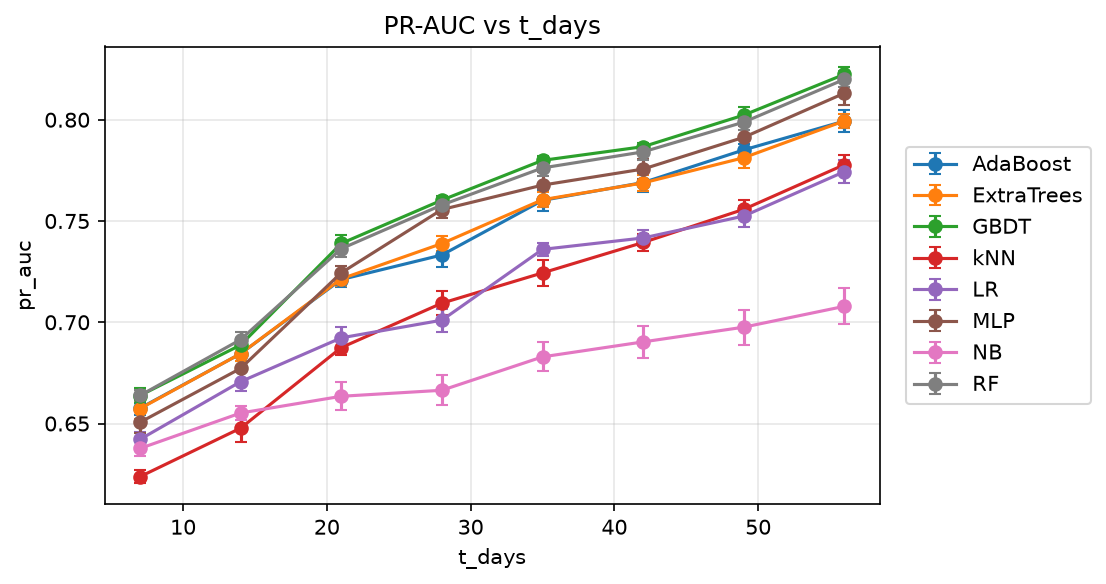

**precision_recall_at10_vs_t_days.png**

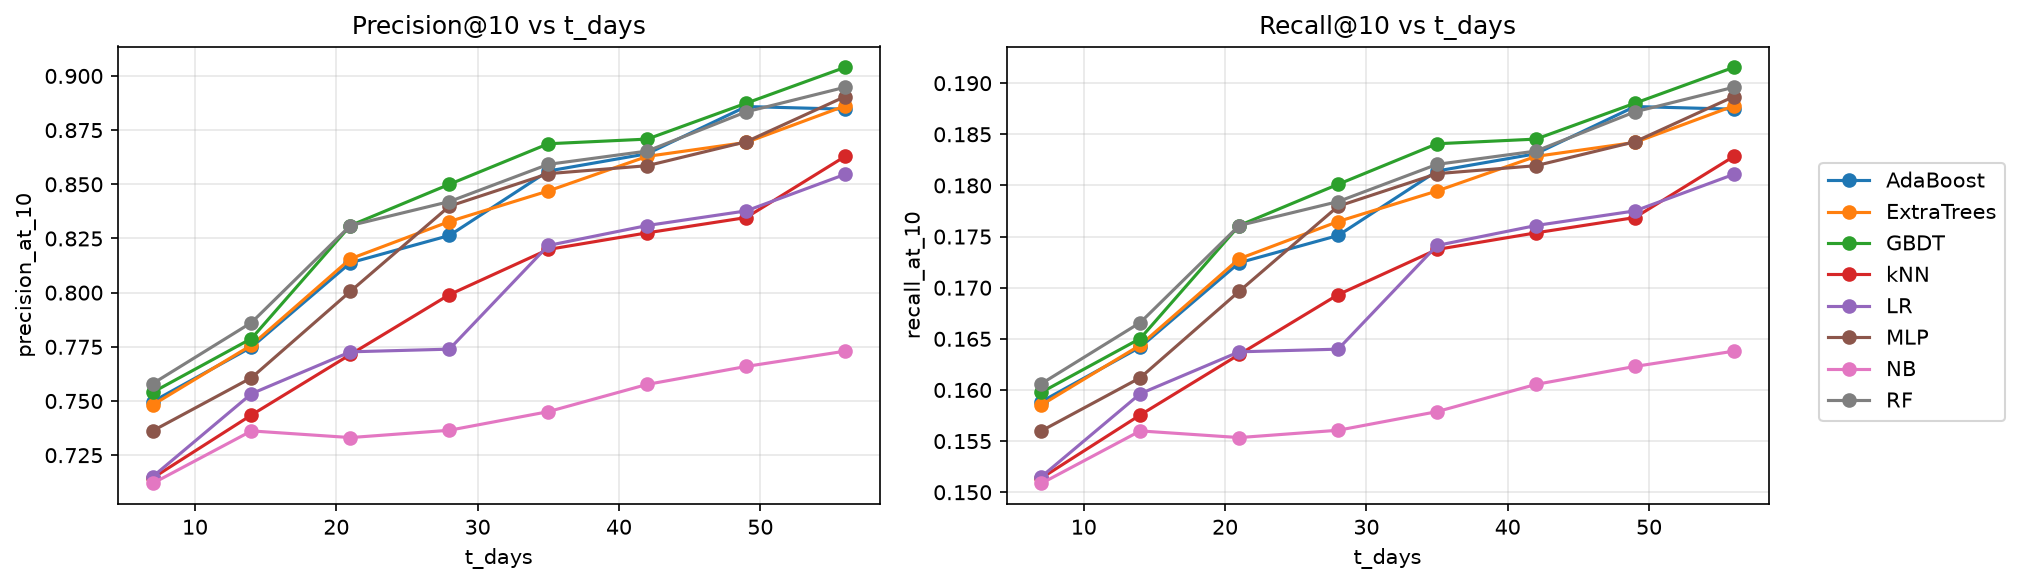

**roc_auc_vs_t_days.png**

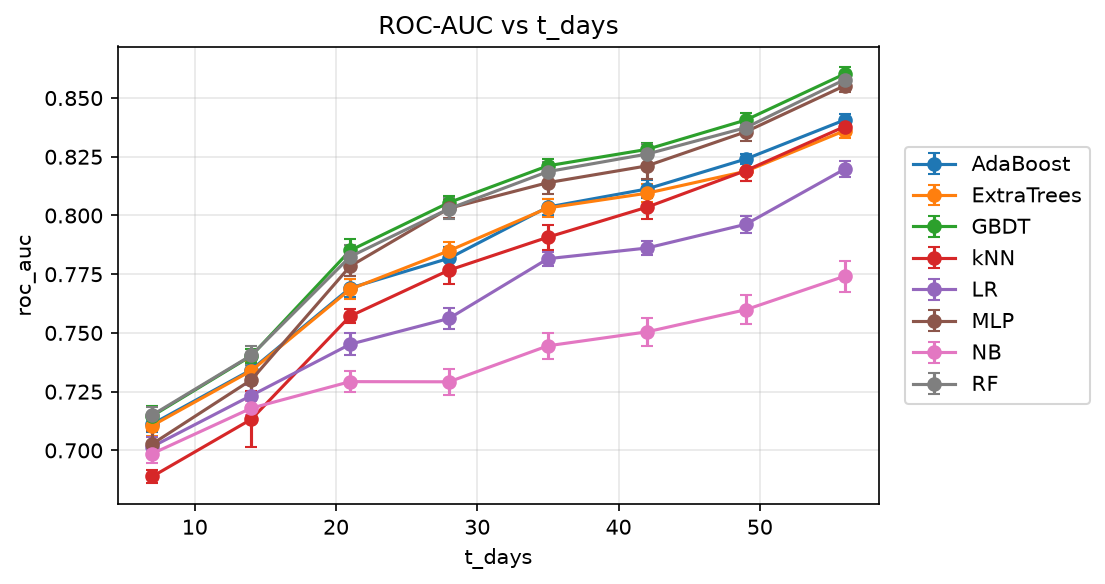

In [9]:
for name, png in full.plots.items():
    display(Markdown(f"**{name}**"))
    display(Image(data=png))

## 6. Comparison with the authors' saved results

Each difference is mine minus the authors', for every model and cut-off day present in both sets of results. `FLAG` marks an absolute difference above 0.01.

In [10]:
KEYS = ["model", "t_days"]
columns = KEYS + list(METRICS)
authors = pd.read_csv(REPO / "example_outputs" / "core" / "results_metrics_summary.csv", usecols=columns)

joined = full.summary[columns].merge(
    authors, on=KEYS, how="outer", suffixes=("_mine", "_authors"), validate="one_to_one", indicator=True
)
matched = joined[joined["_merge"] == "both"].sort_values(KEYS).reset_index(drop=True)
only_authors = joined[joined["_merge"] == "right_only"]
only_mine = joined[joined["_merge"] == "left_only"]

differences = pd.DataFrame(
    {label: matched[f"{column}_mine"] - matched[f"{column}_authors"] for column, label in METRICS.items()}
)
# A missing value cannot be shown to agree, so it is flagged as well.
flags = differences.abs().gt(TOLERANCE) | differences.isna()

comparison = pd.DataFrame({"Model": matched["model"].map(display_model_name), "Day": matched["t_days"]})
comparison = pd.concat([comparison, differences.map(signed)], axis=1)
comparison["Flag"] = flags.any(axis=1).map({True: "FLAG", False: ""})
display(comparison)

print(f"Matched rows: {len(matched)}")
print(f"Flagged rows: {int(flags.any(axis=1).sum())}")
for label, rows_found in (("only in my results", only_mine), ("only in the authors' results", only_authors)):
    if not rows_found.empty:
        print(f"Unmatched rows {label}: {len(rows_found)}, for {', '.join(sorted(rows_found['model'].unique()))}")

,Model,Day,ROC-AUC,PR-AUC,Brier,F1,Precision at 10%,Recall at 10%,Precision at 20%,Recall at 20%,Flag
0,AdaBoost,7,+0.0000,+0.0000,+0.0000,+0.0000,+0.0006,+0.0001,-0.0006,-0.0003,
1,AdaBoost,14,+0.0000,+0.0000,+0.0000,+0.0000,-0.0006,-0.0001,+0.0003,+0.0001,
2,AdaBoost,21,+0.0000,+0.0000,+0.0000,+0.0000,+0.0000,+0.0000,+0.0000,+0.0000,
3,AdaBoost,28,+0.0000,+0.0000,+0.0000,+0.0000,+0.0009,+0.0002,-0.0000,+0.0000,
4,AdaBoost,35,+0.0000,+0.0000,+0.0000,+0.0000,-0.0003,-0.0001,+0.0005,+0.0002,
5,AdaBoost,42,+0.0000,+0.0000,+0.0000,+0.0000,+0.0000,+0.0000,+0.0000,+0.0000,
6,AdaBoost,49,+0.0000,+0.0000,+0.0000,+0.0000,+0.0000,+0.0000,+0.0000,+0.0000,
7,AdaBoost,56,+0.0000,+0.0000,-0.0000,+0.0000,+0.0003,+0.0001,+0.0002,+0.0001,
8,ExtraTrees,7,+0.0000,-0.0000,-0.0000,-0.0000,+0.0000,-0.0000,-0.0002,-0.0001,
9,ExtraTrees,14,+0.0000,+0.0000,+0.0000,-0.0002,+0.0006,+0.0001,+0.0002,+0.0001,


Matched rows: 64
Flagged rows: 0
Unmatched rows only in the authors' results: 16, for svm_linear, svm_rbf


### Largest difference for each metric

In [11]:
absolute = differences.abs()
rows = []
for label in METRICS.values():
    position = absolute[label].idxmax()
    rows.append(
        {
            "Metric": label,
            "Largest difference": absolute[label].max(),
            "Where": f"{display_model_name(matched.loc[position, 'model'])}, day {matched.loc[position, 't_days']}",
        }
    )

largest_differences = pd.DataFrame(rows)
display(largest_differences)

,Metric,Largest difference,Where
0,ROC-AUC,0.0033,"kNN, day 14"
1,PR-AUC,0.0014,"kNN, day 14"
2,Brier,0.0012,"kNN, day 14"
3,F1,0.0005,"RF, day 7"
4,Precision at 10%,0.0049,"kNN, day 49"
5,Recall at 10%,0.0010,"kNN, day 49"
6,Precision at 20%,0.0032,"kNN, day 21"
7,Recall at 20%,0.0014,"kNN, day 21"


## 7. Status

In [12]:
print(f"Quick test: {int(quick_comparison['Within 0.01'].sum())} of {len(quick_comparison)} values within 0.01 of the reference.")
print(f"Full run: {int((~flags.any(axis=1)).sum())} of {len(matched)} model and cut-off combinations within 0.01 on all {len(METRICS)} metrics.")
print(f"Full run time: {full.minutes:.1f} minutes.")
print("Not run yet: the two SVM models and the leakage ablation.")

Quick test: 18 of 18 values within 0.01 of the reference.
Full run: 64 of 64 model and cut-off combinations within 0.01 on all 8 metrics.
Full run time: 19.5 minutes.
Not run yet: the two SVM models and the leakage ablation.


## 8. Remaining runs: SVM models and leakage ablation

These two jobs run outside the notebook, so they keep going if the notebook or VS Code closes. **Keep the Mac on mains power with the lid open**, because `caffeinate -i` does not prevent lid-close sleep.

Unlike the sections above, this section saves files, because the jobs need a log and the comparisons are kept as CSVs. Every cell is safe under Run All: cell 1 will not start a second run, cell 3 stops nothing unless you change it, and cells 4 to 6 wait for the results.

After reopening the notebook, run the setup cell first. It does not start anything.

In [1]:
import os
import re
import shlex
import signal
import subprocess
import sys
import time
from datetime import datetime
from pathlib import Path

import pandas as pd
from IPython.display import display

candidates = [Path.cwd(), Path.cwd() / "leap-early-prediction"]
REPO = next((path for path in candidates if (path / "train_eval.py").exists()), None)
assert REPO is not None, f"Could not find the authors' code from {Path.cwd()}"
sys.path.insert(0, str(REPO))

from config import display_model_name

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
pd.options.display.float_format = "{:.4f}".format

OUTPUTS = REPO / "outputs"
LOG_FILE = OUTPUTS / "run_all.log"
PID_FILE = OUTPUTS / "run_all.pid"
CORE_SUMMARY = OUTPUTS / "results_metrics_summary.csv"
SVM_SUMMARY = REPO / "outputs_svm" / "results_metrics_summary.csv"
ABLATION_SUMMARY = OUTPUTS / "ablation" / "leakage_ablation_summary.csv"
AUTHORS_CORE = REPO / "example_outputs" / "core" / "results_metrics_summary.csv"
AUTHORS_ABLATION = REPO / "example_outputs" / "ablation" / "leakage_ablation_summary.csv"

WINDOWS = [7, 14, 21, 28, 35, 42, 49, 56]
PROTOCOLS = ["strict", "leaky_vle", "leaky_assessment", "leaky_all"]
MODELS = ["lr", "rf", "extratrees", "knn", "nb", "adaboost", "gbdt", "mlp", "svm_linear", "svm_rbf"]

METRICS = {
    "roc_auc_mean": "ROC-AUC",
    "pr_auc_mean": "PR-AUC",
    "brier_mean": "Brier",
    "f1_mean": "F1",
    "precision_at_10_mean": "Precision at 10%",
    "recall_at_10_mean": "Recall at 10%",
    "precision_at_20_mean": "Precision at 20%",
    "recall_at_20_mean": "Recall at 20%",
}
FLAG_LIMITS = {
    "roc_auc_mean": 0.01,
    "pr_auc_mean": 0.01,
    "brier_mean": 0.01,
    "f1_mean": 0.02,
    "precision_at_10_mean": 0.02,
    "recall_at_10_mean": 0.02,
    "precision_at_20_mean": 0.02,
    "recall_at_20_mean": 0.02,
}


def signed(value):
    return f"{value:+.4f}"


def ready(*paths):
    missing = [path for path in paths if not path.exists()]
    for path in missing:
        print("Not available yet:", path.relative_to(REPO))
    return not missing


def saved_pid():
    return int(PID_FILE.read_text().strip()) if PID_FILE.exists() else None


def run_is_alive(pid):
    # Checks the command as well as the number, in case macOS has reused the process ID.
    if pid is None:
        return False
    found = subprocess.run(
        ["ps", "-ww", "-o", "stat=", "-o", "command=", "-p", str(pid)], capture_output=True, text=True
    ).stdout.strip()
    return "leakage_ablation.py" in found and not found.startswith("Z")


def compare_and_show(mine, authors, keys, save_path):
    columns = keys + list(METRICS)
    joined = mine[columns].merge(
        authors[columns], on=keys, how="outer", suffixes=("_mine", "_authors"), validate="one_to_one", indicator=True
    )
    matched = joined[joined["_merge"] == "both"].sort_values(keys).reset_index(drop=True)

    saved = matched[keys].copy()
    for metric in METRICS:
        difference = matched[f"{metric}_mine"] - matched[f"{metric}_authors"]
        saved[f"{metric}_mine"] = matched[f"{metric}_mine"]
        saved[f"{metric}_authors"] = matched[f"{metric}_authors"]
        saved[f"{metric}_diff"] = difference
        # A missing value cannot be shown to agree, so it is flagged as well.
        saved[f"{metric}_flag"] = difference.abs().gt(FLAG_LIMITS[metric]) | difference.isna()
    flag_columns = [f"{metric}_flag" for metric in METRICS]
    saved["flagged"] = saved[flag_columns].any(axis=1)
    saved.to_csv(save_path, index=False)

    view = {}
    for metric, label in METRICS.items():
        view[(label, "Mine")] = saved[f"{metric}_mine"]
        view[(label, "Theirs")] = saved[f"{metric}_authors"]
        view[(label, "Difference")] = saved[f"{metric}_diff"].map(signed)
    view = pd.DataFrame(view)
    view[("Flagged", "")] = saved[flag_columns].apply(
        lambda row: ", ".join(METRICS[name.removesuffix("_flag")] for name in flag_columns if row[name]), axis=1
    )
    labels = saved[keys].copy()
    labels["model"] = labels["model"].map(display_model_name)
    view.index = pd.MultiIndex.from_frame(labels.rename(columns={"model": "Model", "t_days": "Day", "protocol": "Protocol"}))
    display(view)

    rows = []
    for metric, label in METRICS.items():
        absolute = saved[f"{metric}_diff"].abs()
        worst = saved.loc[absolute.idxmax()]
        where = f"{display_model_name(worst['model'])}, day {worst['t_days']}"
        if "protocol" in keys:
            where += f", {worst['protocol']}"
        rows.append(
            {
                "Metric": label,
                "Flag limit": FLAG_LIMITS[metric],
                "Rows compared": len(saved),
                "Flagged rows": int(saved[f"{metric}_flag"].sum()),
                "Largest difference": absolute.max(),
                "Where": where,
            }
        )
    print("Flagged rows per metric")
    display(pd.DataFrame(rows))

    if "protocol" in keys:
        per_protocol = saved.groupby("protocol")[flag_columns + ["flagged"]].sum().reindex(PROTOCOLS)
        per_protocol.columns = [METRICS[name.removesuffix("_flag")] for name in flag_columns] + ["Any metric"]
        per_protocol.insert(0, "Rows compared", saved.groupby("protocol").size())
        per_protocol.index.name = "Protocol"
        print("Flagged rows per protocol")
        display(per_protocol)

    print(f"Rows compared: {len(saved)}. Rows with any flag: {int(saved['flagged'].sum())}.")
    for label, state in (("only in my results", "left_only"), ("only in the authors' results", "right_only")):
        unmatched = joined[joined["_merge"] == state]
        if not unmatched.empty:
            print(f"Unmatched rows {label}: {len(unmatched)}, for {', '.join(sorted(unmatched['model'].unique()))}")
    print("Saved", save_path.relative_to(REPO))
    return saved

### Cell 1: start the runs

Starts the SVM core run, then the leakage ablation, one after the other. The log and process ID go to `outputs/run_all.log` and `outputs/run_all.pid`. The data path is `../Oulab` because the CSVs sit one level above the repo.

In [2]:
DATA_ARGUMENT = "../Oulab"
window_arguments = [str(day) for day in WINDOWS]
JOBS = [
    (
        "SVM core run",
        [
            sys.executable, "main.py", "--data_dir", DATA_ARGUMENT, "--out_dir", "outputs_svm",
            "--windows", *window_arguments, "--models", "svm_linear", "svm_rbf",
        ],
    ),
    (
        "Leakage ablation",
        [
            sys.executable, "leakage_ablation.py", "--data_dir", DATA_ARGUMENT, "--out_dir", "outputs",
            "--windows", *window_arguments, "--models", *MODELS, "--protocols", *PROTOCOLS,
        ],
    ),
]


def stamp(text):
    return f'echo "[$(date "+%Y-%m-%d %H:%M:%S")] {text}"'


def start_runs():
    script = [stamp("RUN START")]
    for number, (name, command) in enumerate(JOBS, start=1):
        script += [
            stamp(f"JOB {number} START: {name}"),
            shlex.join(command),
            "code=$?",
            stamp(f"JOB {number} END: {name}, exit code $code"),
        ]
    script.append(stamp("RUN END"))

    # A notebook sets this variable to its inline plot backend, which the jobs must not inherit.
    environment = {**os.environ, "MPLBACKEND": "Agg"}
    OUTPUTS.mkdir(exist_ok=True)
    with open(LOG_FILE, "ab") as log:
        process = subprocess.Popen(
            ["nohup", "caffeinate", "-i", "/bin/zsh", "-f", "-c", "\n".join(script)],
            cwd=REPO,
            stdin=subprocess.DEVNULL,
            stdout=log,
            stderr=subprocess.STDOUT,
            env=environment,
            start_new_session=True,
        )
    PID_FILE.write_text(str(process.pid))
    print("Started. Process ID:", process.pid)
    print("Log:", LOG_FILE.relative_to(REPO))
    for number, (name, command) in enumerate(JOBS, start=1):
        print(f"\nJob {number}, {name}:\n{shlex.join(['python', *command[1:]])}")


pid = saved_pid()
if run_is_alive(pid):
    print(f"Already running as process {pid}. Nothing was started.")
elif SVM_SUMMARY.exists() or ABLATION_SUMMARY.exists():
    print("Results from an earlier run already exist, so nothing was started. Move them away to run again.")
else:
    start_runs()

Started. Process ID: 72885
Log: outputs/run_all.log

Job 1, SVM core run:
python main.py --data_dir ../Oulab --out_dir outputs_svm --windows 7 14 21 28 35 42 49 56 --models svm_linear svm_rbf

Job 2, Leakage ablation:
python leakage_ablation.py --data_dir ../Oulab --out_dir outputs --windows 7 14 21 28 35 42 49 56 --models lr rf extratrees knn nb adaboost gbdt mlp svm_linear svm_rbf --protocols strict leaky_vle leaky_assessment leaky_all


### Cell 2: check progress

Run this whenever you want an update. The estimate of total time appears once the run has been going for an hour. It is rough, because SVM training time changes with the cut-off day and the protocol.

In [2]:
STAMP = re.compile(r"^\[(\d{4}-\d\d-\d\d \d\d:\d\d:\d\d)\] (.*)$")
CUTOFF = re.compile(r"^(\d{4}-\d\d-\d\d \d\d:\d\d:\d\d),\d+ \| INFO \| Building features at t_days=(\d+)")
JOB_EVENT = re.compile(r"^JOB (\d) (START|END): (.*)$")
ESTIMATE_AFTER_MINUTES = 60
FASTER_MODELS_MINUTES = 2.4  # Minutes per cut-off for the 8 faster models, measured in section 5.
CUTOFFS_IN_JOB = {1: len(WINDOWS), 2: len(PROTOCOLS) * len(WINDOWS)}


def as_time(text):
    return datetime.strptime(text, "%Y-%m-%d %H:%M:%S")


def minutes_between(start, end):
    return (end - start).total_seconds() / 60


def hours_and_minutes(minutes):
    return f"{int(minutes // 60)} h {int(minutes % 60):02d} min"


def read_log():
    lines = LOG_FILE.read_text(errors="replace").splitlines()
    starts = [index for index, line in enumerate(lines) if line.endswith("] RUN START")]
    if not starts:
        return None
    lines = lines[starts[-1]:]
    run = {"lines": lines, "start": None, "end": None, "stopped": False, "last": None}
    run["jobs"] = {number: {"name": None, "start": None, "end": None, "result": None, "cutoffs": []} for number in (1, 2)}
    current = None
    for line in lines:
        stamped, cutoff = STAMP.match(line), CUTOFF.match(line)
        if cutoff and current:
            run["last"] = as_time(cutoff[1])
            run["jobs"][current]["cutoffs"].append(as_time(cutoff[1]))
        elif stamped:
            moment, text = as_time(stamped[1]), stamped[2]
            run["last"] = moment
            event = JOB_EVENT.match(text)
            if text == "RUN START":
                run["start"] = moment
            elif text == "RUN END":
                run["end"] = moment
            elif text.startswith("RUN STOPPED"):
                run["stopped"] = True
            elif event and event[2] == "START":
                current = int(event[1])
                run["jobs"][current].update(name=event[3], start=moment)
            elif event:
                run["jobs"][int(event[1])].update(end=moment, result=event[3])
    return run


def finished_cutoff_minutes(job):
    moments = job["cutoffs"] + ([job["end"]] if job["end"] else [])
    return [minutes_between(first, second) for first, second in zip(moments, moments[1:])]


def show_estimate(run, elapsed):
    job1, job2 = run["jobs"][1], run["jobs"][2]
    job2_minutes = finished_cutoff_minutes(job2)
    job1_minutes = finished_cutoff_minutes(job1)
    if job2_minutes:
        per_cutoff = sum(job2_minutes) / len(job2_minutes)
        total = minutes_between(job1["start"], job1["end"]) + per_cutoff * CUTOFFS_IN_JOB[2]
        basis = f"{len(job2_minutes)} finished cut-offs in the ablation"
        prefix = "about"
    elif job1_minutes:
        per_cutoff = sum(job1_minutes) / len(job1_minutes)
        total = per_cutoff * CUTOFFS_IN_JOB[1] + (per_cutoff + FASTER_MODELS_MINUTES) * CUTOFFS_IN_JOB[2]
        basis = f"{len(job1_minutes)} finished cut-offs in the SVM run"
        prefix = "about"
    else:
        total = elapsed * CUTOFFS_IN_JOB[1] + (elapsed + FASTER_MODELS_MINUTES) * CUTOFFS_IN_JOB[2]
        basis = "no finished cut-offs yet, so this is a lower limit"
        prefix = "at least"
    print(f"Estimated total time: {prefix} {hours_and_minutes(total)}, from {basis}.")


def show_status():
    if not ready(LOG_FILE, PID_FILE):
        return
    pid, run = saved_pid(), read_log()
    if run is None:
        print("The run has only just started, so the log is still empty. Run this cell again in a moment.")
        return
    alive = run_is_alive(pid)
    jobs = run["jobs"]
    current = next((number for number, job in jobs.items() if job["start"] and not job["end"]), None)
    ended_at = run["end"] or (None if alive else run["last"])
    elapsed = minutes_between(run["start"], ended_at or datetime.now())

    print(f"Process {pid} is {'running' if alive else 'not running'}.")
    print(f"Started: {run['start']}")
    print(f"Elapsed: {hours_and_minutes(elapsed)}")
    if run["end"]:
        print("Both jobs have ended.")
    elif run["stopped"]:
        print("The run was stopped by hand.")
    elif not alive:
        print("The process ended before finishing. Check the log below for the reason.")
    elif current:
        job, seen = jobs[current], len(jobs[current]["cutoffs"])
        print(f"Running job {current} of 2: {job['name']}.")
        if seen:
            position = f"Working on cut-off {seen} of {CUTOFFS_IN_JOB[current]}"
            if current == 1:
                print(f"{position}, day {WINDOWS[seen - 1]}.")
            else:
                print(f"{position}, day {WINDOWS[(seen - 1) % len(WINDOWS)]}, protocol {PROTOCOLS[(seen - 1) // len(WINDOWS)]}.")
    for number, job in jobs.items():
        if job["end"]:
            print(f"Job {number} took {hours_and_minutes(minutes_between(job['start'], job['end']))}. {job['result']}.")

    if alive and not run["end"]:
        if elapsed >= ESTIMATE_AFTER_MINUTES:
            show_estimate(run, elapsed)
        else:
            print(f"The total time estimate appears after {ESTIMATE_AFTER_MINUTES} minutes.")

    print("\nLast 20 lines of the log:\n")
    print("\n".join(line[:200] for line in run["lines"][-20:]))


show_status()

Process 72885 is not running.
Started: 2026-11-09 20:26:05
Elapsed: 6 h 42 min
Both jobs have ended.
Job 1 took 1 h 35 min. SVM core run, exit code 0.
Job 2 took 5 h 06 min. Leakage ablation, exit code 0.

Last 20 lines of the log:

/opt/miniconda3/envs/fyp/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedCla
  warnings.warn(
/opt/miniconda3/envs/fyp/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedCla
  warnings.warn(
/opt/miniconda3/envs/fyp/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedCla
  warnings.warn(
/opt/miniconda3/envs/fyp/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` 

### Cell 3: stop the runs safely

**Only use this if you need to stop the runs.** To stop them, change `STOP_NOW` to `True` and run the cell. It checks that the saved process ID is still this run, then stops the whole job.

Neither job can resume. The SVM run saves its results only when it finishes, and the ablation saves results at the end of each protocol.

In [ ]:
STOP_NOW = False  # Change to True only when you want to stop the runs.

if not STOP_NOW:
    print("Nothing was stopped. Set STOP_NOW = True and run this cell again to stop the runs.")
else:
    pid = saved_pid()
    if not run_is_alive(pid):
        print(f"Process {pid} is not this run or has already ended, so nothing was stopped.")
    else:
        os.killpg(pid, signal.SIGTERM)
        for _ in range(20):
            if not run_is_alive(pid):
                break
            time.sleep(0.5)
        if run_is_alive(pid):
            print(f"Process {pid} is still running after the stop signal. Check it in Activity Monitor.")
        else:
            with open(LOG_FILE, "a") as log:
                log.write(f"[{datetime.now():%Y-%m-%d %H:%M:%S}] RUN STOPPED by hand\n")
            print(f"Process {pid} and its jobs have stopped.")

### Cell 4: all 10 models against the authors' core results

Run once both jobs have finished. Saves `outputs/results_all10_summary.csv` and `outputs/reproduction_comparison.csv`. Flag limits are 0.01 for ROC-AUC, PR-AUC and Brier, and 0.02 for F1 and the top-k metrics.

In [3]:
if ready(CORE_SUMMARY, SVM_SUMMARY, AUTHORS_CORE):
    all10 = pd.concat([pd.read_csv(CORE_SUMMARY), pd.read_csv(SVM_SUMMARY)], ignore_index=True)
    all10 = all10.sort_values(["t_days", "model"]).reset_index(drop=True)
    assert not all10.duplicated(["model", "t_days"]).any(), "The same model and day appears in both result files."
    all10.to_csv(OUTPUTS / "results_all10_summary.csv", index=False)
    print(f"Merged {all10['model'].nunique()} models into outputs/results_all10_summary.csv, {len(all10)} rows.")
    reproduction_comparison = compare_and_show(
        all10, pd.read_csv(AUTHORS_CORE), ["model", "t_days"], OUTPUTS / "reproduction_comparison.csv"
    )

Merged 10 models into outputs/results_all10_summary.csv, 80 rows.


ROC-AUC                   PR-AUC                    Brier  \
                  Mine Theirs Difference   Mine Theirs Difference   Mine   
Model      Day                                                             
AdaBoost   7    0.7112 0.7112    +0.0000 0.6576 0.6576    +0.0000 0.2156   
           14   0.7343 0.7343    +0.0000 0.6845 0.6845    +0.0000 0.2123   
           21   0.7691 0.7691    +0.0000 0.7211 0.7211    +0.0000 0.2065   
           28   0.7818 0.7818    +0.0000 0.7332 0.7332    +0.0000 0.2005   
           35   0.8036 0.8036    +0.0000 0.7602 0.7602    +0.0000 0.1937   
           42   0.8113 0.8113    +0.0000 0.7690 0.7690    +0.0000 0.1930   
           49   0.8240 0.8240    +0.0000 0.7851 0.7851    +0.0000 0.1925   
           56   0.8406 0.8406    +0.0000 0.7994 0.7994    +0.0000 0.1891   
ExtraTrees 7    0.7106 0.7106    +0.0000 0.6573 0.6573    -0.0000 0.2149   
           14   0.7339 0.7339    +0.0000 0.6845 0.6845    +0.0000 0.2074   
           21   0.7686 0.7686    -0.0000 0.7214 0.7215    -0.0000 0.1961   
           28   0.7850 0.7850    -0.0000 0.7389 0.7389    -0.0000 0.1908   
           35   0.8032 0.8032    -0.0000 0.7605 0.7605    -0.0000 0.1831   
           42   0.8095 0.8095    -0.0000 0.7688 0.7688    -0.0000 0.1804   
           49   0.8188 0.8188    +0.0000 0.7813 0.7812    +0.0000 0.1769   
           56   0.8361 0.8361    +0.0000 0.7994 0.7994    +0.0000 0.1698   
GBDT       7    0.7147 0.7147    -0.0000 0.6638 0.6638    +0.0000 0.2133   
           14   0.7402 0.7402    +0.0000 0.6888 0.6887    +0.0000 0.2045   
           21   0.7851 0.7851    -0.0000 0.7389 0.7389    -0.0000 0.1878   
           28   0.8055 0.8055    -0.0000 0.7603 0.7603    +0.0000 0.1790   
           35   0.8212 0.8212    +0.0000 0.7799 0.7799    +0.0000 0.1717   
           42   0.8281 0.8281    +0.0000 0.7867 0.7867    +0.0000 0.1682   
           49   0.8406 0.8406    -0.0000 0.8023 0.8023    +0.0000 0.1620   
           56   0.8602 0.8602    +0.0000 0.8224 0.8224    +0.0000 0.1511   
kNN        7    0.6889 0.6861    +0.0028 0.6238 0.6224    +0.0013 0.2250   
           14   0.7132 0.7165    -0.0033 0.6477 0.6492    -0.0014 0.2165   
           21   0.7572 0.7565    +0.0006 0.6875 0.6873    +0.0002 0.1996   
           28   0.7767 0.7766    +0.0002 0.7094 0.7093    +0.0001 0.1913   
           35   0.7908 0.7903    +0.0005 0.7244 0.7242    +0.0002 0.1855   
           42   0.8035 0.8035    +0.0000 0.7394 0.7394    +0.0000 0.1798   
           49   0.8191 0.8189    +0.0002 0.7558 0.7557    +0.0001 0.1725   
           56   0.8378 0.8378    +0.0000 0.7778 0.7778    +0.0000 0.1625   
LR         7    0.7016 0.7016    +0.0000 0.6422 0.6422    +0.0000 0.2176   
           14   0.7234 0.7234    +0.0000 0.6707 0.6707    +0.0000 0.2101   
           21   0.7452 0.7452    -0.0000 0.6923 0.6923    +0.0000 0.2028   
           28   0.7562 0.7562    +0.0000 0.7010 0.7010    +0.0000 0.1991   
           35   0.7816 0.7816    -0.0000 0.7360 0.7360    -0.0000 0.1906   
           42   0.7861 0.7861    +0.0000 0.7416 0.7416    +0.0000 0.1890   
           49   0.7962 0.7962    +0.0000 0.7524 0.7524    +0.0000 0.1854   
           56   0.8197 0.8197    +0.0000 0.7744 0.7744    +0.0000 0.1748   
MLP        7    0.7028 0.7028    +0.0000 0.6506 0.6506    +0.0000 0.2190   
           14   0.7300 0.7300    -0.0000 0.6772 0.6772    -0.0000 0.2091   
           21   0.7784 0.7784    -0.0000 0.7244 0.7244    -0.0000 0.1914   
           28   0.8031 0.8031    +0.0000 0.7557 0.7557    +0.0000 0.1803   
           35   0.8140 0.8140    -0.0000 0.7677 0.7677    -0.0000 0.1753   
           42   0.8211 0.8211    +0.0000 0.7757 0.7757    -0.0000 0.1722   
           49   0.8356 0.8356    +0.0000 0.7913 0.7913    +0.0000 0.1653   
           56   0.8552 0.8552    +0.0000 0.8131 0.8131    +0.0000 0.1548   
NB         7    0.6986 0.6986    +0.0000 0.6377 0.6377    +0.0000 0.2876   
           14   0.7180 0.7180    +0.0000 0.6552 0.6552    +0.00

Flagged rows per metric


,Metric,Flag limit,Rows compared,Flagged rows,Largest difference,Where
0,ROC-AUC,0.0100,80,0,0.0033,"kNN, day 14"
1,PR-AUC,0.0100,80,0,0.0014,"kNN, day 14"
2,Brier,0.0100,80,0,0.0012,"kNN, day 14"
3,F1,0.0200,80,0,0.0005,"RF, day 7"
4,Precision at 10%,0.0200,80,0,0.0049,"kNN, day 49"
5,Recall at 10%,0.0200,80,0,0.0010,"kNN, day 49"
6,Precision at 20%,0.0200,80,0,0.0032,"kNN, day 21"
7,Recall at 20%,0.0200,80,0,0.0014,"kNN, day 21"


Rows compared: 80. Rows with any flag: 0.
Saved outputs/reproduction_comparison.csv


### Cell 5: leakage ablation against the authors' results

Matches on model, cut-off day and protocol, and saves `outputs/ablation_comparison.csv`.

In [4]:
if ready(ABLATION_SUMMARY, AUTHORS_ABLATION):
    ablation_comparison = compare_and_show(
        pd.read_csv(ABLATION_SUMMARY),
        pd.read_csv(AUTHORS_ABLATION),
        ["protocol", "model", "t_days"],
        OUTPUTS / "ablation_comparison.csv",
    )

ROC-AUC                   PR-AUC         \
                                   Mine Theirs Difference   Mine Theirs   
Protocol         Model      Day                                           
leaky_all        AdaBoost   7    0.9590 0.9590    +0.0000 0.9449 0.9449   
                            14   0.9590 0.9590    +0.0000 0.9449 0.9449   
                            21   0.9590 0.9590    +0.0000 0.9449 0.9449   
                            28   0.9590 0.9590    +0.0000 0.9449 0.9449   
                            35   0.9590 0.9590    +0.0000 0.9449 0.9449   
                            42   0.9590 0.9590    +0.0000 0.9449 0.9449   
                            49   0.9590 0.9590    +0.0000 0.9449 0.9449   
                            56   0.9590 0.9590    +0.0000 0.9449 0.9449   
                 ExtraTrees 7    0.9597 0.9597    +0.0000 0.9456 0.9456   
                            14   0.9597 0.9597    +0.0000 0.9456 0.9456   
                            21   0.9597 0.9597    +0.0000 0.9456 0.9456   
                            28   0.9597 0.9597    +0.0000 0.9456 0.9456   
                            35   0.9597 0.9597    +0.0000 0.9456 0.9456   
                            42   0.9597 0.9597    +0.0000 0.9456 0.9456   
                            49   0.9597 0.9597    +0.0000 0.9456 0.9456   
                            56   0.9597 0.9597    +0.0000 0.9456 0.9456   
                 GBDT       7    0.9704 0.9704    -0.0000 0.9602 0.9602   
                            14   0.9704 0.9704    -0.0000 0.9602 0.9602   
                            21   0.9704 0.9704    -0.0000 0.9602 0.9602   
                            28   0.9704 0.9704    -0.0000 0.9602 0.9602   
                            35   0.9704 0.9704    -0.0000 0.9602 0.9602   
                            42   0.9704 0.9704    -0.0000 0.9602 0.9602   
                            49   0.9704 0.9704    -0.0000 0.9602 0.9602   
                            56   0.9704 0.9704    -0.0000 0.9602 0.9602   
                 kNN        7    0.9606 0.9606    +0.0000 0.9346 0.9346   
                            14   0.9606 0.9606    +0.0000 0.9346 0.9346   
                            21   0.9606 0.9606    +0.0000 0.9346 0.9346   
                            28   0.9606 0.9606    +0.0000 0.9346 0.9346   
                            35   0.9606 0.9606    +0.0000 0.9346 0.9346   
                            42   0.9606 0.9606    +0.0000 0.9346 0.9346   
                            49   0.9606 0.9606    +0.0000 0.9346 0.9346   
                            56   0.9606 0.9606    +0.0000 0.9346 0.9346   
                 LR         7    0.9471 0.9471    +0.0000 0.9268 0.9268   
                            14   0.9471 0.9471    +0.0000 0.9268 0.9268   
                            21   0.9471 0.9471    +0.0000 0.9268 0.9268   
                            28   0.9471 0.9471    +0.0000 0.9268 0.9268   
                            35   0.9471 0.9471    +0.0000 0.9268 0.9268   
                            42   0.9471 0.9471    +0.0000 0.9268 0.9268   
                            49   0.9471 0.9471    +0.0000 0.9268 0.9268   
                            56   0.9471 0.9471    +0.0000 0.9268 0.9268   
                 MLP        7    0.9699 0.9699    +0.0000 0.9590 0.9590   
                            14   0.9699 0.9699    +0.0000 0.9590 0.9590   
                            21   0.9699 0.9699    +0.0000 0.9590 0.9590   
                            28   0.9699 0.9699    +0.0000 0.9590 0.9590   
                            35   0.9699 0.9699    +0.0000 0.9590 0.9590   
                            42   0.9699 0.9699    +0.0000 0.9590 0.9590   
                            49   0.9699 0.9699    +0.0000 0.9590 0.9590   
                            56   0.9699 0.9699    +0.0000 0.9590 0.9590   
                 NB         7    0.9165 0.9165    -0.0000 0.8776 0.8776   
                            14   0.9165 0.9165    -0.0000 0.8776 0.8776   
                            21   0.9165 0.9165    -0.0000

Flagged rows per metric


,Metric,Flag limit,Rows compared,Flagged rows,Largest difference,Where
0,ROC-AUC,0.0100,320,0,0.0033,"kNN, day 14, strict"
1,PR-AUC,0.0100,320,0,0.0014,"kNN, day 14, strict"
2,Brier,0.0100,320,0,0.0012,"kNN, day 14, strict"
3,F1,0.0200,320,0,0.0005,"RF, day 7, strict"
4,Precision at 10%,0.0200,320,0,0.0049,"kNN, day 49, strict"
5,Recall at 10%,0.0200,320,0,0.0010,"kNN, day 49, strict"
6,Precision at 20%,0.0200,320,0,0.0041,"kNN, day 7, leaky_assessment"
7,Recall at 20%,0.0200,320,0,0.0018,"kNN, day 7, leaky_assessment"


Flagged rows per protocol


,Rows compared,ROC-AUC,PR-AUC,Brier,F1,Precision at 10%,Recall at 10%,Precision at 20%,Recall at 20%,Any metric
Protocol,,,,,,,,,,
strict,80,0,0,0,0,0,0,0,0,0
leaky_vle,80,0,0,0,0,0,0,0,0,0
leaky_assessment,80,0,0,0,0,0,0,0,0,0
leaky_all,80,0,0,0,0,0,0,0,0,0


Rows compared: 320. Rows with any flag: 0.
Saved outputs/ablation_comparison.csv


### Cell 6: how much leakage inflates ROC-AUC

My ROC-AUC for every model at days 7, 28 and 56 under each protocol.

In [5]:
DAYS_TO_SHOW = [7, 28, 56]
PROTOCOL_ORDER = ["strict", "leaky_assessment", "leaky_vle", "leaky_all"]

if ready(ABLATION_SUMMARY):
    ablation = pd.read_csv(ABLATION_SUMMARY)
    roc_table = ablation[ablation["t_days"].isin(DAYS_TO_SHOW)].pivot(
        index="model", columns=["t_days", "protocol"], values="roc_auc_mean"
    )
    roc_table = roc_table.reindex(columns=pd.MultiIndex.from_product([DAYS_TO_SHOW, PROTOCOL_ORDER]))
    roc_table = roc_table.reindex([model for model in MODELS if model in roc_table.index])
    roc_table.index = roc_table.index.map(display_model_name)
    roc_table.index.name = "Model"
    roc_table.columns.names = ["Day", "Protocol"]
    display(roc_table)

Day            7                                           28  \
Protocol   strict leaky_assessment leaky_vle leaky_all strict   
Model                                                           
LR         0.7016           0.9351    0.8965    0.9471 0.7562   
RF         0.7151           0.9616    0.9140    0.9669 0.8029   
ExtraTrees 0.7106           0.9499    0.8993    0.9597 0.7850   
kNN        0.6889           0.9476    0.9083    0.9606 0.7767   
NB         0.6986           0.8643    0.8536    0.9165 0.7292   
AdaBoost   0.7112           0.9542    0.9020    0.9590 0.7818   
GBDT       0.7147           0.9645    0.9153    0.9704 0.8055   
MLP        0.7028           0.9614    0.9177    0.9699 0.8031   
SVM-Lin    0.6976           0.9340    0.8965    0.9465 0.7468   
SVM-RBF    0.7009           0.9518    0.9003    0.9606 0.7880   

Day                                                 56                   \
Protocol   leaky_assessment leaky_vle leaky_all strict leaky_assessment   
Model                                                                     
LR                   0.9369    0.8969    0.9471 0.8197           0.9364   
RF                   0.9648    0.9261    0.9669 0.8578           0.9651   
ExtraTrees           0.9528    0.9090    0.9597 0.8361           0.9527   
kNN                  0.9525    0.9210    0.9606 0.8378           0.9539   
NB                   0.8699    0.8468    0.9165 0.7741           0.8742   
AdaBoost             0.9553    0.9103    0.9590 0.8406           0.9557   
GBDT                 0.9674    0.9295    0.9704 0.8602           0.9678   
MLP                  0.9658    0.9306    0.9699 0.8552           0.9661   
SVM-Lin              0.9358    0.8962    0.9465 0.8125           0.9354   
SVM-RBF              0.9552    0.9182    0.9606 0.8404           0.9549   

Day                             
Protocol   leaky_vle leaky_all  
Model                           
LR            0.8968    0.9471  
RF            0.9311    0.9669  
ExtraTrees    0.9130    0.9597  
kNN           0.9247    0.9606  
NB            0.8526    0.9165  
AdaBoost      0.9139    0.9590  
GBDT          0.9349    0.9704  
MLP           0.9338    0.9699  
SVM-Lin       0.8969    0.9465  
SVM-RBF       0.9230    0.9606

## Extension: new models on the authors' split

Shared harness for new model families. It imports the authors' code without changing it, rebuilds their strict features for every cut-off day, and reuses their exact stratified 80/20 split for seeds 0 to 4, with y = 1 for Pass or Distinction.

Features are cached in `extension_cache/` and results go to `extension_results/`. Both folders sit in the project folder, next to the repo rather than inside it. The GBDT sanity check must print PASS before any new result is trusted.

In [1]:
# Shared setup. Imports the authors' code and changes none of it.
import logging
import sys
import time
from pathlib import Path

import pandas as pd
from IPython.display import display
from sklearn.model_selection import train_test_split

candidates = [Path.cwd(), Path.cwd() / "leap-early-prediction"]
REPO = next((path for path in candidates if (path / "train_eval.py").exists()), None)
assert REPO is not None, f"Could not find the authors' code from {Path.cwd()}"
PROJECT = REPO.parent
DATA_DIR = PROJECT / "Oulab"
CACHE_DIR = PROJECT / "extension_cache"
RESULTS_DIR = PROJECT / "extension_results"
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

from data_load import load_oulad_data
from features import create_labels, build_features
from metrics import compute_metrics
from config import KEY_COLS, DEFAULT_SEEDS, DEFAULT_TEST_SIZE, DEFAULT_RANDOM_STATE
from train_eval import _build_models, _is_imbalanced, _summarize_metrics

# The reproduction ran before pyarrow was installed, when pandas stored text as plain Python strings.
# Installing pyarrow changes that default, so pin it back to keep the authors' features exactly as reproduced.
pd.set_option("mode.string_storage", "python")

WINDOWS = [7, 14, 21, 28, 35, 42, 49, 56]
SEEDS = DEFAULT_SEEDS
PROTOCOL = "strict"
METRIC_COLS = ["roc_auc", "f1", "pr_auc", "brier", "precision_at_10", "recall_at_10", "precision_at_20", "recall_at_20"]
ROW_COLS = ["t_days", "seed", "model", *METRIC_COLS, "fit_seconds"]

CACHE_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

log = logging.getLogger("extension")
if not log.handlers:
    handler = logging.StreamHandler(sys.stdout)
    handler.setFormatter(logging.Formatter("%(asctime)s | %(message)s", "%Y-%m-%d %H:%M:%S"))
    log.addHandler(handler)
log.setLevel(logging.INFO)
log.propagate = False

print("Interpreter:   ", sys.executable)
print("Authors' code: ", REPO)
print("Data folder:   ", DATA_DIR)
print("Feature cache: ", CACHE_DIR)
print("Results:       ", RESULTS_DIR)
print(f"Windows {WINDOWS}, seeds {SEEDS}, protocol {PROTOCOL!r}, test size {DEFAULT_TEST_SIZE}")

Interpreter:    /opt/miniconda3/envs/fyp/bin/python
Authors' code:  /Users/user/Desktop/FYI/leap-early-prediction
Data folder:    /Users/user/Desktop/FYI/Oulab
Feature cache:  /Users/user/Desktop/FYI/extension_cache
Results:        /Users/user/Desktop/FYI/extension_results
Windows [7, 14, 21, 28, 35, 42, 49, 56], seeds [0, 1, 2, 3, 4], protocol 'strict', test size 0.2


In [2]:
# Features and labels per cut-off day, built exactly as train_eval.run_benchmark builds them,
# then cached as Parquet so later sections skip the slow build.
_raw = {}  # OULAD tables and labels: loaded once, and only if some day is not cached yet
_xy = {}   # t_days -> (X_df, y), kept in memory after the first read


def _oulad():
    if not _raw:
        log.info("Loading OULAD from %s", DATA_DIR)
        data = load_oulad_data(DATA_DIR)
        _raw["data"] = data
        _raw["labels"] = create_labels(data["student_info"])
        log.info("Loaded OULAD: %d labelled enrolments", len(_raw["labels"]))
    return _raw["data"], _raw["labels"]


def _write_parquet(frame, path):
    temporary = path.with_name(path.name + ".tmp")
    frame.to_parquet(temporary)
    temporary.replace(path)  # a crash mid-write never leaves a half-written cache file


def get_xy(t):
    """X_df and y at cut-off day t, from memory, then the cache, then a fresh build."""
    if t in _xy:
        return _xy[t]
    x_path, y_path = CACHE_DIR / f"X_t{t}.parquet", CACHE_DIR / f"y_t{t}.parquet"
    if x_path.exists() and y_path.exists():
        X_df = pd.read_parquet(x_path)
        y = pd.read_parquet(y_path)["y"]
        log.info("t=%d: loaded %d rows from the cache", t, len(X_df))
    else:
        data, labels = _oulad()
        start = time.perf_counter()
        X_df = build_features(data, labels, t, protocol=PROTOCOL)
        y = labels.set_index(KEY_COLS).loc[X_df.index, "y"]
        _write_parquet(X_df, x_path)
        _write_parquet(y.to_frame(), y_path)
        # Prove the cache reads back identical, values, dtypes and row order, before anything uses it.
        pd.testing.assert_frame_equal(pd.read_parquet(x_path), X_df, check_exact=True)
        pd.testing.assert_series_equal(pd.read_parquet(y_path)["y"], y, check_exact=True)
        log.info("t=%d: built %d rows in %.0fs and cached them", t, len(X_df), time.perf_counter() - start)
    assert X_df.index.equals(y.index), f"t={t}: features and labels are not in the same row order"
    _xy[t] = (X_df, y)
    return X_df, y


def get_split(t, seed):
    """The authors' split: the same call as train_eval.run_benchmark, on the same row order."""
    X_df, y = get_xy(t)
    return train_test_split(X_df, y, test_size=DEFAULT_TEST_SIZE, random_state=seed, stratify=y)

In [3]:
# SANITY CHECK. Must print PASS before anything else runs.
# GBDT at day 7, seed 0, built through this harness, must equal the reproduced row to within 1e-9.
SANITY_TOLERANCE = 1e-9
SANITY_PASSED = False
REFERENCE_RUNS = {
    "core run": REPO / "outputs" / "results_metrics_per_window.csv",
    "ablation, strict": REPO / "outputs" / "ablation" / "strict" / "results_metrics_per_window.csv",
}

X_train, X_test, y_train, y_test = get_split(7, 0)
sanity_model = _build_models(["gbdt"], y_train)["gbdt"]
sanity_model.fit(X_train, y_train)
sanity_proba = pd.Series(sanity_model.predict_proba(X_test)[:, 1], index=y_test.index)
sanity_metrics = compute_metrics(y_test.reset_index(drop=True), sanity_proba.reset_index(drop=True))
assert list(sanity_metrics) == METRIC_COLS, f"compute_metrics returned {list(sanity_metrics)}"

rows = []
for run, path in REFERENCE_RUNS.items():
    reference = pd.read_csv(path)
    match = reference[(reference["model"] == "gbdt") & (reference["t_days"] == 7) & (reference["seed"] == 0)]
    assert len(match) == 1, f"{path} has {len(match)} rows for gbdt, day 7, seed 0"
    for metric in METRIC_COLS:
        reproduced = float(match.iloc[0][metric])
        rows.append({"Reference": run, "Metric": metric, "Harness": sanity_metrics[metric],
                     "Reproduction": reproduced, "Difference": sanity_metrics[metric] - reproduced})
sanity = pd.DataFrame(rows)
sanity["Within 1e-9"] = sanity["Difference"].abs() <= SANITY_TOLERANCE  # a missing value counts as a failure
with pd.option_context("display.float_format", "{:.12g}".format):
    display(sanity)

SANITY_PASSED = bool(sanity["Within 1e-9"].all())
print("PASS" if SANITY_PASSED else "FAIL")
assert SANITY_PASSED, "FAIL: the harness split or features differ from the reproduction. Stop and investigate."

2026-11-17 12:05:58 | Loading OULAD from /Users/user/Desktop/FYI/Oulab


2026-11-17 12:06:01 | Loaded OULAD: 32593 labelled enrolments


2026-11-17 12:06:10 | t=7: built 32593 rows in 9s and cached them


,Reference,Metric,Harness,Reproduction,Difference,Within 1e-9
0,core run,roc_auc,0.714284695904,0.714284695904,0,True
1,core run,f1,0.636349130365,0.636349130365,0,True
2,core run,pr_auc,0.661746750163,0.661746750163,0,True
3,core run,brier,0.213226236584,0.213226236584,0,True
4,core run,precision_at_10,0.748466257669,0.748466257669,0,True
5,core run,recall_at_10,0.158596035099,0.158596035099,0,True
6,core run,precision_at_20,0.72009202454,0.72009202454,0,True
7,core run,recall_at_20,0.305167370816,0.305167370816,0,True
8,"ablation, strict",roc_auc,0.714284695904,0.714284695904,0,True
9,"ablation, strict",f1,0.636349130365,0.636349130365,0,True


PASS


In [4]:
# Build and cache the remaining cut-off days, then free the raw OULAD tables.
assert SANITY_PASSED, "Run the sanity check first. It must PASS."
for t in WINDOWS:
    get_xy(t)
_raw.clear()

display(pd.DataFrame([
    {"t_days": t, "Rows": len(_xy[t][0]), "Features": _xy[t][0].shape[1], "Share with y = 1": _xy[t][1].mean()}
    for t in WINDOWS
]))

2026-11-17 12:06:29 | t=14: built 32593 rows in 10s and cached them


2026-11-17 12:06:40 | t=21: built 32593 rows in 11s and cached them


2026-11-17 12:06:51 | t=28: built 32593 rows in 11s and cached them


2026-11-17 12:07:03 | t=35: built 32593 rows in 12s and cached them


2026-11-17 12:07:15 | t=42: built 32593 rows in 12s and cached them


2026-11-17 12:07:28 | t=49: built 32593 rows in 13s and cached them


2026-11-17 12:07:42 | t=56: built 32593 rows in 14s and cached them


,t_days,Rows,Features,Share with y = 1
0,7,32593,11,0.472034
1,14,32593,11,0.472034
2,21,32593,11,0.472034
3,28,32593,11,0.472034
4,35,32593,11,0.472034
5,42,32593,11,0.472034
6,49,32593,11,0.472034
7,56,32593,11,0.472034


In [5]:
def run_family(family_name, make_models):
    """Fit every model from make_models(y_train) on the authors' split, for every day and seed.

    make_models(y_train) returns {model_alias: unfitted_model}. Each finished fit is appended to
    extension_results/<family_name>_per_window.csv straight away, and fits already in that file are
    skipped, so running the same call again after a crash resumes where it stopped. An error stops
    the run rather than skipping the model, so a result is never missing without notice.
    """
    assert SANITY_PASSED, "The sanity check has not passed in this kernel."
    per_window_path = RESULTS_DIR / f"{family_name}_per_window.csv"
    summary_path = RESULTS_DIR / f"{family_name}_summary.csv"

    done = set()
    if per_window_path.exists():
        existing = pd.read_csv(per_window_path)
        if list(existing.columns) != ROW_COLS:
            raise ValueError(f"{per_window_path.name} has columns {list(existing.columns)}, expected {ROW_COLS}")
        done = set(zip(existing["t_days"].astype(int), existing["seed"].astype(int), existing["model"].astype(str)))
        log.info("[%s] resuming: %d fits already saved", family_name, len(done))

    run_start = time.perf_counter()
    new_fits = 0
    for t in WINDOWS:
        for seed in SEEDS:
            X_train, X_test, y_train, y_test = get_split(t, seed)
            for alias, model in make_models(y_train).items():
                if (t, seed, alias) in done:
                    continue
                start = time.perf_counter()
                model.fit(X_train, y_train)
                fit_seconds = time.perf_counter() - start
                classes = list(getattr(model, "classes_", [0, 1]))
                assert classes == [0, 1], f"{alias} has classes {classes}, so column 1 would not be y = 1"
                proba = pd.Series(model.predict_proba(X_test)[:, 1], index=y_test.index)
                metrics = compute_metrics(y_test.reset_index(drop=True), proba.reset_index(drop=True))
                row = {"t_days": t, "seed": seed, "model": alias, **metrics, "fit_seconds": fit_seconds}
                pd.DataFrame([row], columns=ROW_COLS).to_csv(
                    per_window_path, mode="a", header=not per_window_path.exists(), index=False
                )
                done.add((t, seed, alias))
                new_fits += 1
                log.info(
                    "[%s] t=%d seed=%d %s: ROC-AUC %.4f, PR-AUC %.4f, Brier %.4f, fit %.1fs",
                    family_name, t, seed, alias, metrics["roc_auc"], metrics["pr_auc"], metrics["brier"], fit_seconds,
                )

    per_window = pd.read_csv(per_window_path)
    repeated = per_window.duplicated(["t_days", "seed", "model"])
    assert not repeated.any(), f"{per_window_path.name} has {int(repeated.sum())} repeated fits"
    summary = _summarize_metrics(per_window)
    summary.to_csv(summary_path, index=False)
    log.info(
        "[%s] finished: %d new fits in %.0fs, %d in the file. Saved %s",
        family_name, new_fits, time.perf_counter() - run_start, len(per_window), summary_path.name,
    )
    return summary


print("run_family is ready.")

run_family is ready.


### A. Gradient boosting (hyperparameters from Le et al. 2026c, ldt-early-warning)

XGBoost, LightGBM, CatBoost and HistGradientBoosting on the shared harness, for all 8 cut-off days and 5 seeds. Hyperparameters are copied from `ldt-early-warning` at commit `eebb631`. They match the repo, plus CatBoost's `eval_metric="AUC"`, which the repo also sets.

Two deliberate differences keep the models comparable with LEAP. Every model uses seed 42, and class weighting follows LEAP's rule rather than always being on. Under that rule no split is weighted, because y = 1 is 47.2% of every training split.

In [1]:
# Hyperparameters copied, not imported, from:
#   Repo:    https://github.com/lengocluyen/ldt-early-warning
#   Commit:  eebb631addd079c84ac4317432abbb7fc60a6feb
#   Files:   src/ldt_pipeline.py, build_model(), branches for XGB, LGBM, CAT and HGB
#            config/experiment_modern_models.yaml, sections xgboost, lightgbm, catboost and
#            hist_gradient_boosting, plus random_state: 42 and n_jobs: -1
#
# Deliberate differences from that repo, to stay comparable with LEAP:
#   1. Every model is seeded with DEFAULT_RANDOM_STATE (42), as in LEAP. The repo's config also uses 42.
#   2. Class weighting follows LEAP's _is_imbalanced rule. The repo always weights XGB, LGBM and CAT,
#      with neg/pos capped at 20, and never weights HGB.
#
# Output-only settings that the repo does not use:
#   verbose=-1 (LightGBM) silences its training log.
#   allow_writing_files=False (CatBoost) stops it writing a catboost_info folder into the LEAP repo.
#
# Inherited from the repo unchanged:
#   LightGBM's subsample=0.8 has no effect, because bagging also needs subsample_freq > 0.
#   HGB's default early_stopping="auto" is on above 10,000 training rows, so max_iter=300 is a ceiling.
import subprocess

from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from xgboost import XGBClassifier

LDT_REPO = PROJECT / "sota_code" / "ldt-early-warning"
LDT_COMMIT = "eebb631addd079c84ac4317432abbb7fc60a6feb"
ldt_head = subprocess.run(
    ["git", "-C", str(LDT_REPO), "rev-parse", "HEAD"], capture_output=True, text=True, check=True
).stdout.strip()
assert ldt_head == LDT_COMMIT, f"{LDT_REPO.name} is at {ldt_head}, expected {LDT_COMMIT}"
print(f"{LDT_REPO.name} is at the cited commit {LDT_COMMIT}.")

boosting_weighted = []  # one entry per call: True when LEAP's rule switched class weighting on


def make_models(y_train):
    imbalanced = _is_imbalanced(y_train)
    boosting_weighted.append(imbalanced)
    smaller_class = min(y_train.mean(), 1 - y_train.mean())
    if imbalanced:
        neg, pos = int((y_train == 0).sum()), int((y_train == 1).sum())
        xgb_weight = {"scale_pos_weight": neg / pos}
        lgbm_weight = {"class_weight": "balanced"}
        cat_weight = {"auto_class_weights": "Balanced"}
        hgb_weight = {"class_weight": "balanced"}
        log.info("[boosting] class weighting ON: smaller class is %.2f%% of training, below LEAP's 40%%", 100 * smaller_class)
    else:
        xgb_weight, lgbm_weight, cat_weight, hgb_weight = {}, {}, {}, {}
        log.info("[boosting] class weighting OFF: smaller class is %.2f%% of training, LEAP weights only below 40%%", 100 * smaller_class)
    return {
        "xgboost": XGBClassifier(
            objective="binary:logistic", eval_metric="logloss", n_estimators=300, max_depth=3,
            learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, reg_lambda=5, n_jobs=-1,
            random_state=DEFAULT_RANDOM_STATE, **xgb_weight,
        ),
        "lightgbm": LGBMClassifier(
            n_estimators=500, learning_rate=0.05, num_leaves=31, subsample=0.8, colsample_bytree=0.8,
            n_jobs=-1, verbose=-1, random_state=DEFAULT_RANDOM_STATE, **lgbm_weight,
        ),
        "catboost": CatBoostClassifier(
            iterations=500, learning_rate=0.05, depth=6, loss_function="Logloss", eval_metric="AUC",
            verbose=False, thread_count=-1, random_seed=DEFAULT_RANDOM_STATE, allow_writing_files=False,
            **cat_weight,
        ),
        "hgb": HistGradientBoostingClassifier(
            max_iter=300, learning_rate=0.05, l2_regularization=0.1,
            random_state=DEFAULT_RANDOM_STATE, **hgb_weight,
        ),
    }

ldt-early-warning is at the cited commit eebb631addd079c84ac4317432abbb7fc60a6feb.


In [2]:
boosting_weighted.clear()
boosting_summary = run_family("boosting", make_models)
print(f"\nClass weighting was switched on in {sum(boosting_weighted)} of {len(boosting_weighted)} splits.")

2026-11-17 12:13:27 | [boosting] class weighting OFF: smaller class is 47.20% of training, LEAP weights only below 40%


2026-11-17 12:13:27 | [boosting] t=7 seed=0 xgboost: ROC-AUC 0.7157, PR-AUC 0.6670, Brier 0.2128, fit 0.4s


2026-11-17 12:13:31 | [boosting] t=7 seed=0 lightgbm: ROC-AUC 0.7028, PR-AUC 0.6504, Brier 0.2180, fit 3.6s


2026-11-17 12:13:33 | [boosting] t=7 seed=0 catboost: ROC-AUC 0.7143, PR-AUC 0.6618, Brier 0.2135, fit 1.7s


2026-11-17 12:13:33 | [boosting] t=7 seed=0 hgb: ROC-AUC 0.7137, PR-AUC 0.6571, Brier 0.2136, fit 0.7s


2026-11-17 12:13:33 | [boosting] class weighting OFF: smaller class is 47.20% of training, LEAP weights only below 40%


... (192 outputs left out)

2026-11-17 12:17:36 | [boosting] t=56 seed=4 catboost: ROC-AUC 0.8649, PR-AUC 0.8334, Brier 0.1488, fit 1.6s


2026-11-17 12:17:37 | [boosting] t=56 seed=4 hgb: ROC-AUC 0.8614, PR-AUC 0.8269, Brier 0.1506, fit 0.8s


2026-11-17 12:17:37 | [boosting] finished: 160 new fits in 250s, 160 in the file. Saved boosting_summary.csv



Class weighting was switched on in 0 of 40 splits.


In [3]:
# The four new models next to the authors' GBDT and RF from the reproduced core run. Mean ± std over 5 seeds.
COMPARE_DAYS = [7, 28, 56]
COMPARE_METRICS = {"roc_auc": "ROC-AUC", "pr_auc": "PR-AUC", "brier": "Brier (lower is better)", "f1": "F1"}
COMPARE_MODELS = {
    "gbdt": "GBDT (LEAP)", "rf": "RF (LEAP)",
    "xgboost": "XGBoost", "lightgbm": "LightGBM", "catboost": "CatBoost", "hgb": "HGB",
}

leap_summary = pd.read_csv(REPO / "outputs" / "results_metrics_summary.csv")
boosting_summary = pd.read_csv(RESULTS_DIR / "boosting_summary.csv")
both = pd.concat([leap_summary, boosting_summary], ignore_index=True).set_index(["t_days", "model"])
assert both.index.is_unique, "A model and day appears twice across the two summary files."

rows = []
for t in COMPARE_DAYS:
    for model, label in COMPARE_MODELS.items():
        r = both.loc[(t, model)]
        cells = {name: f"{r[f'{m}_mean']:.4f} ± {r[f'{m}_std']:.4f}" for m, name in COMPARE_METRICS.items()}
        rows.append({"Day": t, "Model": label, **cells})
boosting_comparison = pd.DataFrame(rows).set_index(["Day", "Model"])
display(boosting_comparison)

ROC-AUC           PR-AUC Brier (lower is better)  \
Day Model                                                                   
7   GBDT (LEAP)  0.7147 ± 0.0041  0.6638 ± 0.0038         0.2133 ± 0.0016   
    RF (LEAP)    0.7151 ± 0.0035  0.6638 ± 0.0026         0.2132 ± 0.0014   
    XGBoost      0.7157 ± 0.0037  0.6658 ± 0.0025         0.2130 ± 0.0014   
    LightGBM     0.7053 ± 0.0040  0.6520 ± 0.0033         0.2172 ± 0.0015   
    CatBoost     0.7150 ± 0.0047  0.6641 ± 0.0046         0.2134 ± 0.0018   
    HGB          0.7135 ± 0.0034  0.6620 ± 0.0031         0.2137 ± 0.0014   
28  GBDT (LEAP)  0.8055 ± 0.0030  0.7603 ± 0.0023         0.1790 ± 0.0014   
    RF (LEAP)    0.8029 ± 0.0045  0.7579 ± 0.0041         0.1810 ± 0.0018   
    XGBoost      0.8071 ± 0.0039  0.7624 ± 0.0030         0.1781 ± 0.0018   
    LightGBM     0.8057 ± 0.0055  0.7572 ± 0.0053         0.1787 ± 0.0027   
    CatBoost     0.8106 ± 0.0048  0.7659 ± 0.0035         0.1763 ± 0.0024   
    HGB          0.8096 ± 0.0041  0.7643 ± 0.0028         0.1768 ± 0.0020   
56  GBDT (LEAP)  0.8602 ± 0.0028  0.8224 ± 0.0034         0.1511 ± 0.0017   
    RF (LEAP)    0.8578 ± 0.0029  0.8200 ± 0.0039         0.1533 ± 0.0017   
    XGBoost      0.8615 ± 0.0025  0.8233 ± 0.0033         0.1503 ± 0.0016   
    LightGBM     0.8618 ± 0.0031  0.8219 ± 0.0044         0.1498 ± 0.0021   
    CatBoost     0.8648 ± 0.0030  0.8275 ± 0.0044         0.1482 ± 0.0018   
    HGB          0.8637 ± 0.0029  0.8254 ± 0.0022         0.1487 ± 0.0020   

                              F1  
Day Model                         
7   GBDT (LEAP)  0.6416 ± 0.0038  
    RF (LEAP)    0.6474 ± 0.0043  
    XGBoost      0.6426 ± 0.0049  
    LightGBM     0.6295 ± 0.0045  
    CatBoost     0.6424 ± 0.0050  
    HGB          0.6418 ± 0.0030  
28  GBDT (LEAP)  0.7183 ± 0.0037  
    RF (LEAP)    0.7160 ± 0.0053  
    XGBoost      0.7207 ± 0.0032  
    LightGBM     0.7259 ± 0.0068  
    CatBoost     0.7288 ± 0.0060  
    HGB          0.7299 ± 0.0047  
56  GBDT (LEAP)  0.7777 ± 0.0039  
    RF (LEAP)    0.7779 ± 0.0044  
    XGBoost      0.7780 ± 0.0036  
    LightGBM     0.7796 ± 0.0040  
    CatBoost     0.7816 ± 0.0045  
    HGB          0.7839 ± 0.0047

### B. TabPFN (official PriorLabs package)

TabPFN on the shared harness. A pilot at days 7, 28 and 56, seed 0, times one fit and prediction on this Mac. The full grid of 8 days and 5 seeds then runs as a background script, `extension/run_tabpfn.py`, so it doesn't tie up this kernel. That script reuses the cached features and the authors' split call, and repeats the GBDT sanity check before it starts.

**Licence.** The TabPFN weights are not open source. This package uses TabPFN-3.5 by default, released by Prior Labs under the *TABPFN-3.5 License v1.0*, which allows non-commercial use only. The licence explicitly includes academic research, so it is fine for this project, but its outputs may not be used commercially or in production.

Cite TabPFN in the report: Hollmann, N., Müller, S., Purucker, L., Krishnakumar, A., Körfer, M., Hoo, S. B., Schirrmeister, R. T. and Hutter, F. (2025), "Accurate predictions on small data with a tabular foundation model", *Nature* 637, 319–326. Also state the model version, TabPFN-3.5, and the package version, tabpfn 10.1.0.

In [1]:
import torch
import tabpfn
from tabpfn import TabPFNClassifier
from tabpfn.settings import settings as tabpfn_settings

device = "mps" if torch.backends.mps.is_available() else "cpu"
print("tabpfn version:", tabpfn.__version__)
print("Model version: ", tabpfn_settings.tabpfn.model_version.value)
print("Device:        ", device)

tabpfn version: 10.1.0
Model version:  v3.5
Device:         mps


/opt/miniconda3/envs/fyp/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# PILOT: time one fit + predict_proba at days 7, 28 and 56, seed 0, to choose how to run the full grid.
# A small warm-up fit loads the weights first, downloading them on first use, so the timings exclude that.
# If TabPFN needs a licence acceptance or a login, it stops here with instructions. Nothing works around it.
PILOT_DAYS = [7, 28, 56]
PILOT_LIMIT_SECONDS = 10 * 60

X_train, _, y_train, _ = get_split(7, 0)
TabPFNClassifier(device=device, random_state=DEFAULT_RANDOM_STATE).fit(X_train.iloc[:200], y_train.iloc[:200])
log.info("[pilot] weights loaded")

pilot_rows = []
for t in PILOT_DAYS:
    X_train, X_test, y_train, y_test = get_split(t, 0)
    model = TabPFNClassifier(device=device, random_state=DEFAULT_RANDOM_STATE)
    start = time.perf_counter()
    model.fit(X_train, y_train)
    proba = pd.Series(model.predict_proba(X_test)[:, 1], index=y_test.index)
    seconds = time.perf_counter() - start
    metrics = compute_metrics(y_test.reset_index(drop=True), proba.reset_index(drop=True))
    log.info("[pilot] t=%d: fit + predict_proba took %.1fs", t, seconds)
    pilot_rows.append({
        "t_days": t, "Training rows": len(X_train), "Test rows": len(X_test), "Features": X_train.shape[1],
        "Fit + predict (s)": seconds, "ROC-AUC": metrics["roc_auc"],
    })
pilot = pd.DataFrame(pilot_rows)
display(pilot)

PILOT_SLOWEST = float(pilot["Fit + predict (s)"].max())
TABPFN_MODEL = "tabpfn" if PILOT_SLOWEST < PILOT_LIMIT_SECONDS else "tabpfn_sub10k"
print(f"Slowest fit + predict: {PILOT_SLOWEST / 60:.1f} minutes. Full grid runs as {TABPFN_MODEL!r}.")

2026-11-18 21:50:33 | [pilot] weights loaded


2026-11-18 21:54:44 | [pilot] t=7: fit + predict_proba took 251.1s


2026-11-18 22:00:28 | [pilot] t=28: fit + predict_proba took 343.7s


2026-11-18 22:16:19 | [pilot] t=56: fit + predict_proba took 951.1s


,t_days,Training rows,Test rows,Features,Fit + predict (s),ROC-AUC
0,7,26074,6519,11,251.115874,0.721133
1,28,26074,6519,11,343.741239,0.815452
2,56,26074,6519,11,951.137244,0.872267


Slowest fit + predict: 15.9 minutes. Full grid runs as 'tabpfn_sub10k'.


#### Full grid in the background

The pilot cell picks the variant from its timings. If one fit and prediction takes under 10 minutes, the model is `tabpfn` and uses the whole training split as context. Otherwise it is `tabpfn_sub10k`, which passes `inference_config={"SUBSAMPLE_SAMPLES": 10_000}` so each TabPFN estimator sees 10,000 training rows.

The next cell starts `extension/run_tabpfn.py` with `nohup` and `caffeinate`, so the run outlives this kernel and the Mac doesn't idle-sleep. Closing the lid still puts the Mac to sleep and pauses the run, so keep it open. The process ID is saved in `extension_results/tabpfn.pid` and the log in `extension_results/tabpfn_run.log`. Re-run the progress cell to see how many of the 40 runs are done. The summary and table cells only work once all 40 are saved.

In [3]:
# Start the full TabPFN grid as a background process that survives this kernel.
import gc
import os
import subprocess

TABPFN_SCRIPT = PROJECT / "extension" / "run_tabpfn.py"
TABPFN_PID_FILE = RESULTS_DIR / "tabpfn.pid"
TABPFN_LOG = RESULTS_DIR / "tabpfn_run.log"
TABPFN_CSV = RESULTS_DIR / "tabpfn_per_window.csv"
TABPFN_RUNS = len(WINDOWS) * len(SEEDS)


def tabpfn_running():
    """The background run's process ID while it is alive, otherwise None."""
    if not TABPFN_PID_FILE.exists():
        return None
    pid = int(TABPFN_PID_FILE.read_text().strip())
    command = subprocess.run(["ps", "-p", str(pid), "-o", "command="], capture_output=True, text=True).stdout
    return pid if "run_tabpfn.py" in command else None  # guards against a reused process ID


def tabpfn_done(model_name):
    if not TABPFN_CSV.exists():
        return 0
    return int((pd.read_csv(TABPFN_CSV)["model"] == model_name).sum())


if tabpfn_running():
    print(f"Already running as process {tabpfn_running()}, so no second copy was started.")
else:
    assert "TABPFN_MODEL" in globals(), "Run the pilot cell first. It chooses the model."
    if tabpfn_done(TABPFN_MODEL) == TABPFN_RUNS:
        print(f"All {TABPFN_RUNS} {TABPFN_MODEL} runs are already saved, so nothing was started.")
    else:
        # Free the pilot's GPU memory before the background process starts using the same GPU.
        globals().pop("model", None)
        gc.collect()
        if device == "mps":
            torch.mps.empty_cache()
        with open(TABPFN_LOG, "a") as log_file:
            process = subprocess.Popen(
                ["nohup", "caffeinate", "-is", sys.executable, str(TABPFN_SCRIPT), "--model", TABPFN_MODEL],
                cwd=PROJECT, stdin=subprocess.DEVNULL, stdout=log_file, stderr=subprocess.STDOUT,
                start_new_session=True,
            )
        TABPFN_PID_FILE.write_text(f"{process.pid}\n")
        print(f"Started {TABPFN_MODEL} as process {process.pid}.")
        print(f"Log: {TABPFN_LOG}")
        print(f"To stop it safely: os.killpg({process.pid}, signal.SIGTERM). Starting it again resumes the run.")

Started tabpfn_sub10k as process 44241.
Log: /Users/user/Desktop/FYI/extension_results/tabpfn_run.log
To stop it safely: os.killpg(44241, signal.SIGTERM). Starting it again resumes the run.


#### Full training context (`tabpfn`)

The pilot chose the 10k-context variant because one full-context fit took 15.9 minutes at day 56. The next cell runs the same 40-run grid again as `tabpfn`, with no `SUBSAMPLE_SAMPLES` limit, so each TabPFN estimator sees the whole training split of 26,074 rows. It uses the same script, split, seeds and results file, and the `model` column tells the two variants apart.

Expect roughly 5 to 8 hours with the lid open. The progress cell below shows both variants. The summary and table cells include every variant that has all 40 runs saved.

In [1]:
# Start the full-context TabPFN grid in the background: model "tabpfn", no SUBSAMPLE_SAMPLES limit.
# Self-contained, so it works in a fresh kernel without re-running the pilot.
import subprocess

TABPFN_SCRIPT = PROJECT / "extension" / "run_tabpfn.py"
TABPFN_PID_FILE = RESULTS_DIR / "tabpfn.pid"
TABPFN_LOG = RESULTS_DIR / "tabpfn_run.log"
TABPFN_CSV = RESULTS_DIR / "tabpfn_per_window.csv"
TABPFN_RUNS = len(WINDOWS) * len(SEEDS)
FULL_CONTEXT_MODEL = "tabpfn"


def tabpfn_running():
    """The background run's process ID while it is alive, otherwise None."""
    if not TABPFN_PID_FILE.exists():
        return None
    pid = int(TABPFN_PID_FILE.read_text().strip())
    command = subprocess.run(["ps", "-p", str(pid), "-o", "command="], capture_output=True, text=True).stdout
    return pid if "run_tabpfn.py" in command else None  # guards against a reused process ID


def tabpfn_done(model_name):
    if not TABPFN_CSV.exists():
        return 0
    return int((pd.read_csv(TABPFN_CSV)["model"] == model_name).sum())


if tabpfn_running():
    print(f"A TabPFN run is already going as process {tabpfn_running()}, so no second copy was started.")
elif tabpfn_done(FULL_CONTEXT_MODEL) == TABPFN_RUNS:
    print(f"All {TABPFN_RUNS} {FULL_CONTEXT_MODEL} runs are already saved, so nothing was started.")
else:
    with open(TABPFN_LOG, "a") as log_file:
        process = subprocess.Popen(
            ["nohup", "caffeinate", "-is", sys.executable, str(TABPFN_SCRIPT), "--model", FULL_CONTEXT_MODEL],
            cwd=PROJECT, stdin=subprocess.DEVNULL, stdout=log_file, stderr=subprocess.STDOUT,
            start_new_session=True,
        )
    TABPFN_PID_FILE.write_text(f"{process.pid}\n")
    print(f"Started {FULL_CONTEXT_MODEL} as process {process.pid}, resuming from {tabpfn_done(FULL_CONTEXT_MODEL)} saved runs.")
    print(f"Log: {TABPFN_LOG}")
    print(f"To stop it safely: os.killpg({process.pid}, signal.SIGTERM). Starting it again resumes the run.")

Started tabpfn as process 66311, resuming from 0 saved runs.
Log: /Users/user/Desktop/FYI/extension_results/tabpfn_run.log
To stop it safely: os.killpg(66311, signal.SIGTERM). Starting it again resumes the run.


In [2]:
# Progress of the background TabPFN runs, one line per variant. Re-run this cell to refresh.
saved_counts = pd.read_csv(TABPFN_CSV)["model"].value_counts() if TABPFN_CSV.exists() else pd.Series(dtype=int)
for variant in ["tabpfn_sub10k", "tabpfn"]:
    print(f"{variant}: {int(saved_counts.get(variant, 0))} of {TABPFN_RUNS} runs done.")
pid = tabpfn_running()
print(f"Background process: {f'running as {pid}' if pid else 'not running'}.")
if TABPFN_LOG.exists():
    print("\nLast log lines:")
    print("\n".join(TABPFN_LOG.read_text().splitlines()[-3:]))

tabpfn_sub10k: 40 of 40 runs done.
tabpfn: 0 of 40 runs done.
Background process: running as 66311.

Last log lines:
2026-11-19 18:14:58 | 39/40 t=56 seed=3 tabpfn_sub10k: ROC-AUC 0.8683, PR-AUC 0.8298, Brier 0.1454, fit 0.5s, predict 66.1s
2026-11-19 18:16:05 | 40/40 t=56 seed=4 tabpfn_sub10k: ROC-AUC 0.8714, PR-AUC 0.8378, Brier 0.1449, fit 0.4s, predict 66.1s
2026-11-19 18:16:05 | Finished: 40 of 40 runs saved for tabpfn_sub10k


In [2]:
# Summarise every TabPFN variant that has all 40 runs saved, with the authors' _summarize_metrics:
# mean and std over seeds. A variant still running is listed but left out until it finishes.
tabpfn_rows = pd.read_csv(TABPFN_CSV)
assert not tabpfn_rows.duplicated(["t_days", "seed", "model"]).any(), "a run appears twice"
all_runs = {(t, s) for t in WINDOWS for s in SEEDS}
complete = [m for m, rows in tabpfn_rows.groupby("model") if set(zip(rows["t_days"], rows["seed"])) == all_runs]
incomplete = sorted(set(tabpfn_rows["model"]) - set(complete))
assert complete, "No TabPFN variant has all 40 runs yet. Wait for the background run to finish."

tabpfn_summary = _summarize_metrics(tabpfn_rows[tabpfn_rows["model"].isin(complete)])
tabpfn_summary.to_csv(RESULTS_DIR / "tabpfn_summary.csv", index=False)
print(f"Saved tabpfn_summary.csv for {', '.join(complete)}.")
for model_name in complete:
    rows = tabpfn_rows[tabpfn_rows["model"] == model_name]
    print(f"  {model_name}: mean time per run, fit {rows['fit_seconds'].mean():.0f}s, predict {rows['predict_seconds'].mean():.0f}s.")
if incomplete:
    print(f"Not summarised yet, runs still missing: {', '.join(incomplete)}.")

Saved tabpfn_summary.csv for tabpfn_sub10k: 8 cut-off days from 40 runs.
Mean time per run: fit 1s, predict 81s.


In [3]:
# TabPFN next to the authors' GBDT and RF from the reproduced core run. Mean ± std over 5 seeds.
COMPARE_DAYS = [7, 28, 56]
COMPARE_METRICS = {"roc_auc": "ROC-AUC", "pr_auc": "PR-AUC", "brier": "Brier (lower is better)", "f1": "F1"}
tabpfn_summary = pd.read_csv(RESULTS_DIR / "tabpfn_summary.csv")
TABPFN_LABELS = {"tabpfn_sub10k": "TabPFN (10k context)", "tabpfn": "TabPFN (full context)"}
TABPFN_MODELS = {"gbdt": "GBDT (LEAP)", "rf": "RF (LEAP)"}
TABPFN_MODELS.update({m: label for m, label in TABPFN_LABELS.items() if m in set(tabpfn_summary["model"])})

leap_summary = pd.read_csv(REPO / "outputs" / "results_metrics_summary.csv")
both = pd.concat([leap_summary, tabpfn_summary], ignore_index=True).set_index(["t_days", "model"])
assert both.index.is_unique, "A model and day appears twice across the two summary files."

rows = []
for t in COMPARE_DAYS:
    for model_name, label in TABPFN_MODELS.items():
        r = both.loc[(t, model_name)]
        cells = {name: f"{r[f'{m}_mean']:.4f} ± {r[f'{m}_std']:.4f}" for m, name in COMPARE_METRICS.items()}
        rows.append({"Day": t, "Model": label, **cells})
tabpfn_comparison = pd.DataFrame(rows).set_index(["Day", "Model"])
display(tabpfn_comparison)

ROC-AUC           PR-AUC  \
Day Model                                                    
7   GBDT (LEAP)           0.7147 ± 0.0041  0.6638 ± 0.0038   
    RF (LEAP)             0.7151 ± 0.0035  0.6638 ± 0.0026   
    TabPFN (10k context)  0.7184 ± 0.0041  0.6689 ± 0.0033   
28  GBDT (LEAP)           0.8055 ± 0.0030  0.7603 ± 0.0023   
    RF (LEAP)             0.8029 ± 0.0045  0.7579 ± 0.0041   
    TabPFN (10k context)  0.8158 ± 0.0039  0.7737 ± 0.0030   
56  GBDT (LEAP)           0.8602 ± 0.0028  0.8224 ± 0.0034   
    RF (LEAP)             0.8578 ± 0.0029  0.8200 ± 0.0039   
    TabPFN (10k context)  0.8714 ± 0.0023  0.8354 ± 0.0033   

                         Brier (lower is better)               F1  
Day Model                                                          
7   GBDT (LEAP)                  0.2133 ± 0.0016  0.6416 ± 0.0038  
    RF (LEAP)                    0.2132 ± 0.0014  0.6474 ± 0.0043  
    TabPFN (10k context)         0.2122 ± 0.0015  0.6470 ± 0.0027  
28  GBDT (LEAP)                  0.1790 ± 0.0014  0.7183 ± 0.0037  
    RF (LEAP)                    0.1810 ± 0.0018  0.7160 ± 0.0053  
    TabPFN (10k context)         0.1739 ± 0.0021  0.7339 ± 0.0047  
56  GBDT (LEAP)                  0.1511 ± 0.0017  0.7777 ± 0.0039  
    RF (LEAP)                    0.1533 ± 0.0017  0.7779 ± 0.0044  
    TabPFN (10k context)         0.1442 ± 0.0015  0.7895 ± 0.0031

### C. TabTransformer (Le et al. 2026c code, ldt-early-warning, MIT)

The ldt-early-warning repo's own TabTransformer, imported unchanged from `src/models/tab_transformer.py` at commit `eebb631`, under its MIT licence. It runs on the CPU with its default hyperparameters and seed 42, on the shared harness for all 8 cut-off days and 5 seeds.

**What `TabTransformerClassifier` does**, read from the source file:

- **Standardisation.** `fit` z-scores each of the 11 features with the mean and standard deviation of the data it is given, here the 80% training split. A zero standard deviation is replaced by 1. `predict_proba` reuses those training statistics, so the test split never shapes the scaling. The statistics do include the rows later held out for validation.
- **Validation split.** Inside `fit`, a stratified `train_test_split` holds out `val_fraction` = 15% of the training split, with `random_state` = 42. That leaves about 22,160 rows for training and 3,910 for validation. The network learns from the 85% only, and there is no final refit on the whole training split. The test split is never involved.
- **Early stopping.** After every epoch it computes the loss on the validation rows. An epoch counts as an improvement only if that loss drops by more than 0.00001. Training stops after `patience` = 8 epochs without improvement, or at `max_epochs` = 50, and the best weights are then restored.
- **Loss and `pos_weight`.** The loss is `BCEWithLogitsLoss` with `pos_weight` = negatives / positives, counted on the 85% inner training rows. Here y = 1 is 47.2% of the data, so `pos_weight` is about 1.12, which upweights Pass and Distinction. The validation loss for early stopping is weighted the same way.
- **Model.** Each feature becomes a token: a linear projection of its value plus a learned feature embedding. A 2-layer pre-norm Transformer encoder follows, with 4 heads, width 64, GELU and dropout 0.1. Its output is mean-pooled over the tokens and passed to a small MLP head. Training uses AdamW with learning rate 0.001, weight decay 0.0001 and batches of 256, seeded through `torch.manual_seed` and a seeded data loader.
- **Output.** The class has no `classes_` attribute. Column 1 of `predict_proba` is the sigmoid of a logit trained against y, so it is P(y = 1) by construction.

**Note on class weighting.** The other extension models follow LEAP's rule and are unweighted, but this loss always applies `pos_weight`. Upweighting y = 1 pushes the predicted probabilities towards Pass/Distinction, so they are less well calibrated. That can raise the Brier score, and it moves F1 at the 0.5 threshold. ROC-AUC and PR-AUC depend only on the ranking and are less sensitive to it.

In [1]:
# TabTransformer imported unchanged from the ldt-early-warning repo (MIT licence).
#   Repo:    https://github.com/lengocluyen/ldt-early-warning
#   Commit:  eebb631addd079c84ac4317432abbb7fc60a6feb
#   File:    src/models/tab_transformer.py, class TabTransformerClassifier
# The repo goes at the END of sys.path, so the authors' LEAP modules always win a name clash.
# That matters because the repo also has a top-level folder called config.
import subprocess
import warnings

LDT_REPO = PROJECT / "sota_code" / "ldt-early-warning"
LDT_COMMIT = "eebb631addd079c84ac4317432abbb7fc60a6feb"
ldt_head = subprocess.run(
    ["git", "-C", str(LDT_REPO), "rev-parse", "HEAD"], capture_output=True, text=True, check=True
).stdout.strip()
assert ldt_head == LDT_COMMIT, f"{LDT_REPO.name} is at {ldt_head}, expected {LDT_COMMIT}"
if str(LDT_REPO) not in sys.path:
    sys.path.append(str(LDT_REPO))

import src.models.tab_transformer as tab_transformer_module
from src.models.tab_transformer import TabTransformerClassifier

print("Imported from:", tab_transformer_module.__file__)

# PyTorch warns for every model that nested tensors are off when norm_first=True. It changes nothing, so silence it.
warnings.filterwarnings("ignore", message="enable_nested_tensor is True")

EXPECTED_DEFAULTS = {
    "d_model": 64, "n_heads": 4, "n_layers": 2, "dropout": 0.1, "lr": 1e-3, "weight_decay": 1e-4,
    "batch_size": 256, "max_epochs": 50, "patience": 8, "val_fraction": 0.15,
}
defaults = TabTransformerClassifier(random_state=DEFAULT_RANDOM_STATE, device="cpu")
actual_defaults = {name: getattr(defaults, name) for name in EXPECTED_DEFAULTS}
assert actual_defaults == EXPECTED_DEFAULTS, f"defaults differ: {actual_defaults}"
print("Default hyperparameters as expected:", actual_defaults)


def make_tabtransformer(y_train):
    """Default hyperparameters, seed 42, CPU. Its loss always applies pos_weight, whatever LEAP's rule says."""
    return {"tabtransformer": TabTransformerClassifier(random_state=DEFAULT_RANDOM_STATE, device="cpu")}

Imported from: /Users/user/Desktop/FYI/sota_code/ldt-early-warning/src/models/tab_transformer.py
Default hyperparameters as expected: {'d_model': 64, 'n_heads': 4, 'n_layers': 2, 'dropout': 0.1, 'lr': 0.001, 'weight_decay': 0.0001, 'batch_size': 256, 'max_epochs': 50, 'patience': 8, 'val_fraction': 0.15}


In [2]:
# Leakage check: TabTransformer must never see X_test during fit.
# 1. fit takes only x and y, and run_family passes X_train and y_train.
# 2. The scaling statistics equal X_train's own, so no test row shaped them.
# 3. Each test probability depends only on its own row: reversing the test rows gives the same values.
import inspect

import numpy as np

fit_arguments = list(inspect.signature(TabTransformerClassifier.fit).parameters)
assert fit_arguments == ["self", "x", "y"], fit_arguments

X_train, X_test, y_train, y_test = get_split(7, 0)
assert X_train.index.intersection(X_test.index).empty, "the training and test splits share rows"
check_model = TabTransformerClassifier(random_state=DEFAULT_RANDOM_STATE, device="cpu", max_epochs=2).fit(X_train, y_train)

train_values = X_train.to_numpy(np.float32)
train_std = train_values.std(axis=0, keepdims=True)
train_std[train_std == 0] = 1.0
assert np.array_equal(check_model.mean_, train_values.mean(axis=0, keepdims=True)), "the scaling mean is not X_train's"
assert np.array_equal(check_model.std_, train_std), "the scaling standard deviation is not X_train's"

forward = check_model.predict_proba(X_test)[:, 1]
backward = check_model.predict_proba(X_test.iloc[::-1])[:, 1][::-1]
assert np.allclose(forward, backward, atol=1e-6), "test predictions depend on other test rows"
print(f"PASS: fit sees only the {len(X_train):,} training rows, and test predictions are made row by row.")

PASS: fit sees only the 26,074 training rows, and test predictions are made row by row.


In [3]:
# About 80 to 90 minutes on this Mac: one fit takes 1 to 3 minutes, longer at later days as early stopping waits longer.
tabtransformer_summary = run_family("tabtransformer", make_tabtransformer)

2026-11-18 12:07:50 | [tabtransformer] t=7 seed=0 tabtransformer: ROC-AUC 0.7162, PR-AUC 0.6642, Brier 0.2145, fit 70.6s


2026-11-18 12:09:19 | [tabtransformer] t=7 seed=1 tabtransformer: ROC-AUC 0.7196, PR-AUC 0.6652, Brier 0.2120, fit 89.2s


2026-11-18 12:10:38 | [tabtransformer] t=7 seed=2 tabtransformer: ROC-AUC 0.7092, PR-AUC 0.6531, Brier 0.2164, fit 78.2s


2026-11-18 12:12:36 | [tabtransformer] t=7 seed=3 tabtransformer: ROC-AUC 0.7063, PR-AUC 0.6592, Brier 0.2162, fit 118.1s


2026-11-18 12:15:41 | [tabtransformer] t=7 seed=4 tabtransformer: ROC-AUC 0.7123, PR-AUC 0.6595, Brier 0.2157, fit 185.1s


2026-11-18 12:17:08 | [tabtransformer] t=14 seed=0 tabtransformer: ROC-AUC 0.7400, PR-AUC 0.6877, Brier 0.2069, fit 86.6s


... (31 outputs left out)

2026-11-18 15:07:34 | [tabtransformer] t=56 seed=2 tabtransformer: ROC-AUC 0.8608, PR-AUC 0.8228, Brier 0.1512, fit 160.8s


2026-11-18 15:09:24 | [tabtransformer] t=56 seed=3 tabtransformer: ROC-AUC 0.8541, PR-AUC 0.8126, Brier 0.1542, fit 109.6s


2026-11-18 15:11:37 | [tabtransformer] t=56 seed=4 tabtransformer: ROC-AUC 0.8608, PR-AUC 0.8258, Brier 0.1513, fit 132.9s


2026-11-18 15:11:37 | [tabtransformer] finished: 40 new fits in 5325s, 40 in the file. Saved tabtransformer_summary.csv


In [4]:
# TabTransformer next to the authors' GBDT and RF from the reproduced core run. Mean ± std over 5 seeds.
COMPARE_DAYS = [7, 28, 56]
COMPARE_METRICS = {"roc_auc": "ROC-AUC", "pr_auc": "PR-AUC", "brier": "Brier (lower is better)", "f1": "F1"}
TABTRANSFORMER_MODELS = {"gbdt": "GBDT (LEAP)", "rf": "RF (LEAP)", "tabtransformer": "TabTransformer"}

leap_summary = pd.read_csv(REPO / "outputs" / "results_metrics_summary.csv")
tabtransformer_summary = pd.read_csv(RESULTS_DIR / "tabtransformer_summary.csv")
both = pd.concat([leap_summary, tabtransformer_summary], ignore_index=True).set_index(["t_days", "model"])
assert both.index.is_unique, "A model and day appears twice across the two summary files."

rows = []
for t in COMPARE_DAYS:
    for model, label in TABTRANSFORMER_MODELS.items():
        r = both.loc[(t, model)]
        cells = {name: f"{r[f'{m}_mean']:.4f} ± {r[f'{m}_std']:.4f}" for m, name in COMPARE_METRICS.items()}
        rows.append({"Day": t, "Model": label, **cells})
tabtransformer_comparison = pd.DataFrame(rows).set_index(["Day", "Model"])
display(tabtransformer_comparison)

ROC-AUC           PR-AUC Brier (lower is better)  \
Day Model                                                                      
7   GBDT (LEAP)     0.7147 ± 0.0041  0.6638 ± 0.0038         0.2133 ± 0.0016   
    RF (LEAP)       0.7151 ± 0.0035  0.6638 ± 0.0026         0.2132 ± 0.0014   
    TabTransformer  0.7127 ± 0.0054  0.6603 ± 0.0048         0.2149 ± 0.0018   
28  GBDT (LEAP)     0.8055 ± 0.0030  0.7603 ± 0.0023         0.1790 ± 0.0014   
    RF (LEAP)       0.8029 ± 0.0045  0.7579 ± 0.0041         0.1810 ± 0.0018   
    TabTransformer  0.7998 ± 0.0056  0.7503 ± 0.0057         0.1811 ± 0.0027   
56  GBDT (LEAP)     0.8602 ± 0.0028  0.8224 ± 0.0034         0.1511 ± 0.0017   
    RF (LEAP)       0.8578 ± 0.0029  0.8200 ± 0.0039         0.1533 ± 0.0017   
    TabTransformer  0.8606 ± 0.0040  0.8215 ± 0.0054         0.1509 ± 0.0023   

                                 F1  
Day Model                            
7   GBDT (LEAP)     0.6416 ± 0.0038  
    RF (LEAP)       0.6474 ± 0.0043  
    TabTransformer  0.6604 ± 0.0112  
28  GBDT (LEAP)     0.7183 ± 0.0037  
    RF (LEAP)       0.7160 ± 0.0053  
    TabTransformer  0.7309 ± 0.0081  
56  GBDT (LEAP)     0.7777 ± 0.0039  
    RF (LEAP)       0.7779 ± 0.0044  
    TabTransformer  0.7857 ± 0.0039

### D. Sequence models (architecture from Le et al. 2026b, SC2R repo, MIT)

GRU, LSTM and BiLSTM from `extension/rnn_sc2r.py`. That file reproduces the architecture and training loop of `train_rnn_sequence` in `src/cbe_cf/models/train.py` of the SC2R repo, at commit `7bd8523`, under its MIT licence. Its header holds the licence notice and lists every change from their function. In short:

1. It is a class with `fit(seq, static, y)` and `predict_proba(seq, static)`, with no file reading or writing.
2. The inputs are built here rather than taken from their 3 click-window segments. The sequence has one step for all pre-course activity, `date < 0`, then one step per week, `week = date // 7`, up to day t. Each step holds total clicks, active days and unique resources, and students with no activity get zeros. The static inputs are LEAP's 11 features for day t.
3. Validation is 15% of the training rows, stratified with `random_state=42`, instead of their held-out course presentations. The test rows never reach `fit`.
4. Standardisation uses the remaining 85% of training rows only, as theirs uses its training presentations only.
5. Each run is seeded with its LEAP split seed through `random`, NumPy and `torch.manual_seed`, instead of their default 1337.
6. The device is chosen by a one-run test below. Theirs uses CUDA if present, otherwise CPU. Only `gru`, `lstm` and `bilstm` are offered, without their plain `rnn`.

LEAP's strict filter keeps day t itself (`date <= t`) and every cut-off is a multiple of 7, so the last step holds day t alone. Every run goes through `get_split(t, seed)` and `run_family`, so the training and test rows match every other model exactly.

In [1]:
# SC2R sequence models: extension/rnn_sc2r.py, adapted from the SC2R repo (MIT licence).
#   Repo:    https://github.com/lengocluyen/semantics-constrained-counterfactuel-recourse
#   Commit:  7bd85230dcb099e94885cdbc2373780778c6bd39
#   File:    src/cbe_cf/models/train.py, function train_rnn_sequence
import subprocess

import numpy as np
import torch

SC2R_REPO = PROJECT / "sota_code" / "semantics-constrained-counterfactuel-recourse"
SC2R_EXPECTED = "7bd85230dcb099e94885cdbc2373780778c6bd39"
sc2r_head = subprocess.run(
    ["git", "-C", str(SC2R_REPO), "rev-parse", "HEAD"], capture_output=True, text=True, check=True
).stdout.strip()
assert sc2r_head == SC2R_EXPECTED, f"{SC2R_REPO.name} is at {sc2r_head}, expected {SC2R_EXPECTED}"

if str(PROJECT / "extension") not in sys.path:
    sys.path.append(str(PROJECT / "extension"))
import rnn_sc2r
from rnn_sc2r import ARCHS, SeqClassifier

assert rnn_sc2r.SC2R_COMMIT == SC2R_EXPECTED
print("Imported from:", rnn_sc2r.__file__)
print(f"SC2R repo at the cited commit {SC2R_EXPECTED}. Architectures: {ARCHS}")

Imported from: /Users/user/Desktop/FYI/extension/rnn_sc2r.py
SC2R repo at the cited commit 7bd85230dcb099e94885cdbc2373780778c6bd39. Architectures: ('gru', 'lstm', 'bilstm')


In [2]:
# Sequence inputs per cut-off day, from studentVle with LEAP's strict filter (date <= t), for the same
# students in the same row order as X_df. Cached as Parquet next to the static features.
SEQ_CHANNELS = ["clicks", "active_days", "unique_resources"]
_seq = {}


def build_sequences(t):
    X_df, _ = get_xy(t)
    data, _ = _oulad()
    keys = X_df.index.to_frame(index=False)
    keys["position"] = np.arange(len(keys))
    vle = data["student_vle"]
    vle = vle.loc[vle["date"] <= t, KEY_COLS + ["date", "id_site", "sum_click"]].merge(keys, on=KEY_COLS, how="inner")

    n_rows, n_steps = len(X_df), t // 7 + 2  # step 0: every pre-course day; step k >= 1: week k - 1
    date = vle["date"].to_numpy()
    cell = vle["position"].to_numpy() * n_steps + np.where(date < 0, 0, date // 7 + 1)
    size = n_rows * n_steps
    seq = np.zeros((n_rows, n_steps, len(SEQ_CHANNELS)))
    seq[:, :, 0] = np.bincount(cell, weights=vle["sum_click"].to_numpy(float), minlength=size).reshape(n_rows, n_steps)
    seq[:, :, 1] = np.bincount(pd.DataFrame({"cell": cell, "date": date}).drop_duplicates()["cell"], minlength=size).reshape(n_rows, n_steps)
    seq[:, :, 2] = np.bincount(pd.DataFrame({"cell": cell, "site": vle["id_site"].to_numpy()}).drop_duplicates()["cell"], minlength=size).reshape(n_rows, n_steps)

    # The steps must add up to LEAP's own features for the same day.
    assert np.array_equal(seq[:, :, 0].sum(axis=1), X_df["total_clicks_t"].to_numpy()), f"t={t}: clicks differ from LEAP"
    assert np.array_equal(seq[:, :, 1].sum(axis=1), X_df["active_days_t"].to_numpy()), f"t={t}: active days differ from LEAP"
    assert (seq[:, :, 2].max(axis=1) <= X_df["unique_resources_t"].to_numpy()).all(), f"t={t}: resources exceed LEAP's"
    assert (seq[X_df["total_clicks_t"].to_numpy() == 0] == 0).all(), f"t={t}: inactive students have non-zero steps"
    return seq


def get_sequences(t):
    """Sequence array [students, steps, 3] at day t, rows in X_df order: memory, then cache, then a fresh build."""
    if t in _seq:
        return _seq[t]
    X_df, _ = get_xy(t)
    path = CACHE_DIR / f"seq_t{t}.parquet"
    if path.exists():
        frame = pd.read_parquet(path)
        assert frame.index.equals(X_df.index), f"t={t}: cached sequences are not in X_df row order"
        seq = frame.to_numpy().reshape(len(frame), -1, len(SEQ_CHANNELS))
    else:
        seq = build_sequences(t)
        columns = [f"step{k}_{channel}" for k in range(seq.shape[1]) for channel in SEQ_CHANNELS]
        frame = pd.DataFrame(seq.reshape(len(seq), -1), index=X_df.index, columns=columns)
        _write_parquet(frame, path)
        pd.testing.assert_frame_equal(pd.read_parquet(path), frame, check_exact=True)
        log.info("t=%d: built %d-step sequences and cached them", t, seq.shape[1])
    _seq[t] = seq
    return seq


for t in WINDOWS:
    get_sequences(t)
_raw.clear()

display(pd.DataFrame([
    {"t_days": t, "Students": len(_seq[t]), "Steps": _seq[t].shape[1],
     "Students with no activity": int((_seq[t].sum(axis=(1, 2)) == 0).sum()),
     "Mean clicks per student": _seq[t][:, :, 0].sum(axis=1).mean()}
    for t in WINDOWS
]))
print("Every day: step clicks and active days add up exactly to LEAP's total_clicks_t and active_days_t.")

2026-11-19 22:09:19 | Loading OULAD from /Users/user/Desktop/FYI/Oulab


2026-11-19 22:09:22 | Loaded OULAD: 32593 labelled enrolments


2026-11-19 22:09:23 | t=7: built 3-step sequences and cached them


2026-11-19 22:09:23 | t=14: built 4-step sequences and cached them


2026-11-19 22:09:24 | t=21: built 5-step sequences and cached them


2026-11-19 22:09:25 | t=28: built 6-step sequences and cached them


... (2 outputs left out)

2026-11-19 22:09:29 | t=49: built 9-step sequences and cached them


2026-11-19 22:09:31 | t=56: built 10-step sequences and cached them


,t_days,Students,Steps,Students with no activity,Mean clicks per student
0,7,32593,3,5469,133.963520
1,14,32593,4,4512,190.080754
2,21,32593,5,3997,259.747001
3,28,32593,6,3801,309.690118
4,35,32593,7,3686,355.295401
5,42,32593,8,3620,392.859142
6,49,32593,9,3550,434.759703
7,56,32593,10,3510,472.639861


Every day: step clicks and active days add up exactly to LEAP's total_clicks_t and active_days_t.


In [3]:
# Device: CPU unless the Mac's GPU (MPS) is clearly faster, taken here as at least 25% faster, in one run.
# The test fits the heaviest model, BiLSTM, on the longest sequences, day 56, seed 0.
X_train, X_test, y_train, y_test = get_split(56, 0)
train_rows = get_xy(56)[0].index.get_indexer(X_train.index)
device_seconds = {}
for candidate in ["cpu", "mps"] if torch.backends.mps.is_available() else ["cpu"]:
    start = time.perf_counter()
    SeqClassifier("bilstm", seed=0, device=candidate).fit(get_sequences(56)[train_rows], X_train.to_numpy(), y_train.to_numpy())
    device_seconds[candidate] = time.perf_counter() - start
    log.info("[sequence] device test: BiLSTM, day 56, on %s took %.1fs", candidate, device_seconds[candidate])

SEQ_DEVICE = "mps" if device_seconds.get("mps", float("inf")) < 0.75 * device_seconds["cpu"] else "cpu"
print(f"Using {SEQ_DEVICE!r} for all sequence models.")

2026-11-19 22:10:25 | [sequence] device test: BiLSTM, day 56, on cpu took 53.3s


2026-11-19 22:11:07 | [sequence] device test: BiLSTM, day 56, on mps took 42.3s


Using 'cpu' for all sequence models.


In [4]:
class SequenceModel:
    """Lets run_family drive SeqClassifier on the authors' split.

    run_family passes X_train and X_test only. Their index locates each student's sequence row, and the
    training rows identify the run: the cut-off day is the one whose cached features equal X_train, and
    the seed is the one whose split produces these training rows. Anything but exactly one match stops.
    """

    def __init__(self, arch, device):
        self.arch = arch
        self.device = device

    @staticmethod
    def _rows(X):
        rows = get_xy(WINDOWS[0])[0].index.get_indexer(X.index)  # same students and order on every day
        assert (rows >= 0).all(), "some rows are not in the cached features"
        return rows

    def locate(self, X_train):
        rows = self._rows(X_train)
        days = [t for t in WINDOWS if np.array_equal(get_xy(t)[0].to_numpy()[rows], X_train.to_numpy())]
        assert len(days) == 1, f"training rows match cut-off days {days}, expected exactly one"
        seeds = [s for s in SEEDS if get_split(days[0], s)[0].index.equals(X_train.index)]
        assert len(seeds) == 1, f"training rows match seeds {seeds}, expected exactly one"
        return rows, days[0], seeds[0]

    def fit(self, X_train, y_train):
        rows, self.t_, self.seed_ = self.locate(X_train)
        self.model_ = SeqClassifier(self.arch, seed=self.seed_, device=self.device).fit(
            get_sequences(self.t_)[rows], X_train.to_numpy(), y_train.to_numpy()
        )
        return self

    def predict_proba(self, X_test):
        rows = self._rows(X_test)
        assert np.array_equal(get_xy(self.t_)[0].to_numpy()[rows], X_test.to_numpy()), "test rows are not from the fitted day"
        return self.model_.predict_proba(get_sequences(self.t_)[rows], X_test.to_numpy())


def make_sequence_models(y_train):
    return {arch: SequenceModel(arch, SEQ_DEVICE) for arch in ARCHS}


# Check the adapter on two runs: it finds the right day and seed, its sequence rows line up with X_train,
# and the training and test rows never overlap.
for t, seed in [(7, 0), (56, 3)]:
    X_train, X_test, y_train, y_test = get_split(t, seed)
    rows, found_day, found_seed = SequenceModel("gru", SEQ_DEVICE).locate(X_train)
    assert (found_day, found_seed) == (t, seed), (found_day, found_seed)
    assert np.array_equal(get_sequences(t)[rows, :, 0].sum(axis=1), X_train["total_clicks_t"].to_numpy())
    assert not set(rows) & set(SequenceModel._rows(X_test)), "training and test rows overlap"
print("PASS: the adapter finds each run's day and seed, and its sequence rows match X_train exactly.")

PASS: the adapter finds each run's day and seed, and its sequence rows match X_train exactly.


In [5]:
# 3 architectures x 8 days x 5 seeds = 120 fits, about an hour on this Mac.
sequence_summary = run_family("sequence", make_sequence_models)

2026-11-19 22:11:19 | [sequence] t=7 seed=0 gru: ROC-AUC 0.7237, PR-AUC 0.6745, Brier 0.2112, fit 11.8s


2026-11-19 22:11:32 | [sequence] t=7 seed=0 lstm: ROC-AUC 0.7234, PR-AUC 0.6748, Brier 0.2108, fit 13.4s


2026-11-19 22:11:54 | [sequence] t=7 seed=0 bilstm: ROC-AUC 0.7231, PR-AUC 0.6736, Brier 0.2111, fit 21.5s


2026-11-19 22:12:06 | [sequence] t=7 seed=1 gru: ROC-AUC 0.7245, PR-AUC 0.6674, Brier 0.2103, fit 12.0s


2026-11-19 22:12:20 | [sequence] t=7 seed=1 lstm: ROC-AUC 0.7264, PR-AUC 0.6696, Brier 0.2097, fit 13.6s


2026-11-19 22:12:42 | [sequence] t=7 seed=1 bilstm: ROC-AUC 0.7258, PR-AUC 0.6702, Brier 0.2099, fit 22.0s


... (111 outputs left out)

2026-11-19 23:00:03 | [sequence] t=56 seed=4 gru: ROC-AUC 0.8484, PR-AUC 0.8087, Brier 0.1585, fit 23.5s


2026-11-19 23:00:31 | [sequence] t=56 seed=4 lstm: ROC-AUC 0.8498, PR-AUC 0.8085, Brier 0.1574, fit 28.2s


2026-11-19 23:01:22 | [sequence] t=56 seed=4 bilstm: ROC-AUC 0.8498, PR-AUC 0.8098, Brier 0.1578, fit 51.2s


2026-11-19 23:01:22 | [sequence] finished: 120 new fits in 3015s, 120 in the file. Saved sequence_summary.csv


In [6]:
# GRU, LSTM and BiLSTM next to the authors' GBDT and RF from the reproduced core run. Mean ± std over 5 seeds.
COMPARE_DAYS = [7, 28, 56]
COMPARE_METRICS = {"roc_auc": "ROC-AUC", "pr_auc": "PR-AUC", "brier": "Brier (lower is better)", "f1": "F1"}
SEQUENCE_MODELS = {"gbdt": "GBDT (LEAP)", "rf": "RF (LEAP)", "gru": "GRU", "lstm": "LSTM", "bilstm": "BiLSTM"}

leap_summary = pd.read_csv(REPO / "outputs" / "results_metrics_summary.csv")
sequence_summary = pd.read_csv(RESULTS_DIR / "sequence_summary.csv")
both = pd.concat([leap_summary, sequence_summary], ignore_index=True).set_index(["t_days", "model"])
assert both.index.is_unique, "A model and day appears twice across the two summary files."

rows = []
for t in COMPARE_DAYS:
    for model_name, label in SEQUENCE_MODELS.items():
        r = both.loc[(t, model_name)]
        cells = {name: f"{r[f'{m}_mean']:.4f} ± {r[f'{m}_std']:.4f}" for m, name in COMPARE_METRICS.items()}
        rows.append({"Day": t, "Model": label, **cells})
sequence_comparison = pd.DataFrame(rows).set_index(["Day", "Model"])
display(sequence_comparison)

ROC-AUC           PR-AUC Brier (lower is better)  \
Day Model                                                                   
7   GBDT (LEAP)  0.7147 ± 0.0041  0.6638 ± 0.0038         0.2133 ± 0.0016   
    RF (LEAP)    0.7151 ± 0.0035  0.6638 ± 0.0026         0.2132 ± 0.0014   
    GRU          0.7194 ± 0.0043  0.6693 ± 0.0032         0.2122 ± 0.0014   
    LSTM         0.7201 ± 0.0046  0.6701 ± 0.0031         0.2119 ± 0.0016   
    BiLSTM       0.7198 ± 0.0044  0.6702 ± 0.0029         0.2121 ± 0.0015   
28  GBDT (LEAP)  0.8055 ± 0.0030  0.7603 ± 0.0023         0.1790 ± 0.0014   
    RF (LEAP)    0.8029 ± 0.0045  0.7579 ± 0.0041         0.1810 ± 0.0018   
    GRU          0.7819 ± 0.0034  0.7266 ± 0.0035         0.1883 ± 0.0016   
    LSTM         0.7852 ± 0.0037  0.7324 ± 0.0043         0.1872 ± 0.0019   
    BiLSTM       0.7848 ± 0.0046  0.7309 ± 0.0045         0.1872 ± 0.0019   
56  GBDT (LEAP)  0.8602 ± 0.0028  0.8224 ± 0.0034         0.1511 ± 0.0017   
    RF (LEAP)    0.8578 ± 0.0029  0.8200 ± 0.0039         0.1533 ± 0.0017   
    GRU          0.8462 ± 0.0038  0.8030 ± 0.0048         0.1589 ± 0.0018   
    LSTM         0.8477 ± 0.0032  0.8040 ± 0.0034         0.1580 ± 0.0017   
    BiLSTM       0.8469 ± 0.0041  0.8018 ± 0.0061         0.1583 ± 0.0020   

                              F1  
Day Model                         
7   GBDT (LEAP)  0.6416 ± 0.0038  
    RF (LEAP)    0.6474 ± 0.0043  
    GRU          0.6439 ± 0.0076  
    LSTM         0.6459 ± 0.0116  
    BiLSTM       0.6469 ± 0.0069  
28  GBDT (LEAP)  0.7183 ± 0.0037  
    RF (LEAP)    0.7160 ± 0.0053  
    GRU          0.6982 ± 0.0101  
    LSTM         0.7012 ± 0.0101  
    BiLSTM       0.7025 ± 0.0027  
56  GBDT (LEAP)  0.7777 ± 0.0039  
    RF (LEAP)    0.7779 ± 0.0044  
    GRU          0.7630 ± 0.0056  
    LSTM         0.7626 ± 0.0053  
    BiLSTM       0.7641 ± 0.0031

## Extension results

This section gathers every model on the authors' split: the authors' 10 models from the reproduced strict run, and every extension model in `extension_results/`. It never refits anything, so it runs in seconds and doesn't need the harness. **Re-run it after each new section.** It picks up any `<name>_summary.csv` and `<name>_per_window.csv` in `extension_results/` with the LEAP columns, so section E's survival models join in automatically once they are saved that way.

The paired comparison uses the authors' best model at each day, taken as the highest mean ROC-AUC among their 10 models. On the reproduced numbers that is RF at days 7 and 14 and GBDT from day 21. Every model's seed s uses the same split, so each new model is compared with the reference seed by seed.

In [1]:
# Combine the authors' 10-model strict summary with every extension summary into all_models_summary.csv.
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Markdown, display

candidates = [Path.cwd(), Path.cwd() / "leap-early-prediction"]
REPO = next((path for path in candidates if (path / "train_eval.py").exists()), None)
assert REPO is not None, f"Could not find the authors' code from {Path.cwd()}"
RESULTS_DIR = REPO.parent / "extension_results"
FIGURES_DIR = RESULTS_DIR / "figures"
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
from config import display_model_name

LEAP_SUMMARY = REPO / "outputs" / "results_all10_summary.csv"
LEAP_PER_WINDOW = REPO / "outputs" / "results_metrics_per_window.csv"
ALL_METRICS = ["roc_auc", "f1", "pr_auc", "brier", "precision_at_10", "recall_at_10", "precision_at_20", "recall_at_20"]
SUMMARY_COLS = ["t_days", "model", *[f"{m}_{stat}" for m in ALL_METRICS for stat in ("mean", "std")]]

# Families in section order. A new summary file (section E, say) takes the next place automatically.
FAMILY_NAMES = {"boosting": "Gradient boosting", "tabpfn": "TabPFN", "tabtransformer": "TabTransformer", "sequence": "Sequence models"}
NEW_MODEL_NAMES = {
    "xgboost": "XGBoost", "lightgbm": "LightGBM", "catboost": "CatBoost", "hgb": "HGB",
    "tabpfn": "TabPFN (full context)", "tabpfn_sub10k": "TabPFN (10k context)", "tabtransformer": "TabTransformer",
    "gru": "GRU", "lstm": "LSTM", "bilstm": "BiLSTM",
}


def model_label(model):
    return NEW_MODEL_NAMES.get(model, display_model_name(model))


leap_summary = pd.read_csv(LEAP_SUMMARY)
assert set(SUMMARY_COLS) <= set(leap_summary.columns) and leap_summary["model"].nunique() == 10
parts = [leap_summary[SUMMARY_COLS].assign(group="LEAP", source="leap")]
included, skipped = [], []
for path in sorted(RESULTS_DIR.glob("*_summary.csv")):
    if path.name == "all_models_summary.csv":
        continue
    frame = pd.read_csv(path)
    if not set(SUMMARY_COLS) <= set(frame.columns):
        skipped.append(path.name)  # not in the LEAP summary format, e.g. survival-only metrics
        continue
    parts.append(frame[SUMMARY_COLS].assign(group="extension", source=path.name.removesuffix("_summary.csv")))
    included.append(path.name)

all_models = pd.concat(parts, ignore_index=True)[["group", "source", *SUMMARY_COLS]]
repeated = all_models.duplicated(["t_days", "model"])
assert not repeated.any(), f"model and day appear twice: {all_models.loc[repeated, ['source', 'model', 't_days']].values.tolist()}"
FAMILY_ORDER = [s for s in FAMILY_NAMES if s in set(all_models["source"])] + sorted(
    set(all_models.loc[all_models["group"] == "extension", "source"]) - set(FAMILY_NAMES)
)
all_models["source"] = pd.Categorical(all_models["source"], ["leap", *FAMILY_ORDER], ordered=True)
all_models = all_models.sort_values(["source", "model", "t_days"]).reset_index(drop=True)
all_models["source"] = all_models["source"].astype(str)
all_models.to_csv(RESULTS_DIR / "all_models_summary.csv", index=False)

print(f"Included: {LEAP_SUMMARY.name} (authors' 10 models) and {', '.join(included)}")
if skipped:
    print(f"Skipped, not in the LEAP summary format: {', '.join(skipped)}")
overview = all_models.groupby(["group", "source"], sort=False).agg(models=("model", "nunique"), days=("t_days", "nunique"))
display(overview)
print(f"Saved {RESULTS_DIR / 'all_models_summary.csv'}: {all_models['model'].nunique()} models, {len(all_models)} rows.")

Included: results_all10_summary.csv (authors' 10 models) and boosting_summary.csv, sequence_summary.csv, tabpfn_summary.csv, tabtransformer_summary.csv


models  days
group     source                      
LEAP      leap                10     8
extension boosting             4     8
          tabpfn               1     8
          tabtransformer       1     8
          sequence             3     8

Saved /Users/user/Desktop/FYI/extension_results/all_models_summary.csv: 19 models, 152 rows.


In [2]:
# 1. Top 5 models per day by mean ROC-AUC over the 5 seeds, across the authors' models and the extension.
def source_label(source):
    return "LEAP" if source == "leap" else FAMILY_NAMES.get(source, source.title())


ranked = all_models.sort_values(["t_days", "roc_auc_mean"], ascending=[True, False]).copy()
ranked["Rank"] = ranked.groupby("t_days").cumcount() + 1
top5 = ranked[ranked["Rank"] <= 5]
top5_table = top5.assign(
    cell=[f"{model_label(m)}, {source_label(s)}: {v:.4f}" for m, s, v in zip(top5["model"], top5["source"], top5["roc_auc_mean"])]
).pivot(index="Rank", columns="t_days", values="cell")
top5_table.columns = [f"Day {t}" for t in top5_table.columns]
with pd.option_context("display.max_colwidth", None):
    display(top5_table)

,Day 7,Day 14,Day 21,Day 28,Day 35,Day 42,Day 49,Day 56
Rank,,,,,,,,
1,"LSTM, Sequence models: 0.7201","LSTM, Sequence models: 0.7467","TabPFN (10k context), TabPFN: 0.7959","TabPFN (10k context), TabPFN: 0.8158","TabPFN (10k context), TabPFN: 0.8301","TabPFN (10k context), TabPFN: 0.8384","TabPFN (10k context), TabPFN: 0.8518","TabPFN (10k context), TabPFN: 0.8714"
2,"BiLSTM, Sequence models: 0.7198","BiLSTM, Sequence models: 0.7462","CatBoost, Gradient boosting: 0.7887","CatBoost, Gradient boosting: 0.8106","CatBoost, Gradient boosting: 0.8245","CatBoost, Gradient boosting: 0.8322","CatBoost, Gradient boosting: 0.8449","CatBoost, Gradient boosting: 0.8648"
3,"GRU, Sequence models: 0.7194","GRU, Sequence models: 0.7461","HGB, Gradient boosting: 0.7871","HGB, Gradient boosting: 0.8096","HGB, Gradient boosting: 0.8235","HGB, Gradient boosting: 0.8307","HGB, Gradient boosting: 0.8440","HGB, Gradient boosting: 0.8637"
4,"TabPFN (10k context), TabPFN: 0.7184","TabPFN (10k context), TabPFN: 0.7460","XGBoost, Gradient boosting: 0.7864","XGBoost, Gradient boosting: 0.8071","XGBoost, Gradient boosting: 0.8225","XGBoost, Gradient boosting: 0.8302","XGBoost, Gradient boosting: 0.8425","LightGBM, Gradient boosting: 0.8618"
5,"XGBoost, Gradient boosting: 0.7157","XGBoost, Gradient boosting: 0.7424","GBDT, LEAP: 0.7851","LightGBM, Gradient boosting: 0.8057","GBDT, LEAP: 0.8212","LightGBM, Gradient boosting: 0.8285","LightGBM, Gradient boosting: 0.8420","XGBoost, Gradient boosting: 0.8615"


In [3]:
# 2. Paired comparison with the authors' best model on each day (highest mean ROC-AUC among their 10).
# Seed s is the same split for every model, so differences are taken seed by seed, then averaged.
# "Better" is strict: higher ROC-AUC or PR-AUC, lower Brier. A tie does not count.
PAIRED_METRICS = {"roc_auc": "ROC-AUC", "pr_auc": "PR-AUC", "brier": "Brier"}
RUN_COLS = ["t_days", "seed", "model", *PAIRED_METRICS]

reference = leap_summary.loc[leap_summary.groupby("t_days")["roc_auc_mean"].idxmax(), ["t_days", "model"]]
reference = reference.rename(columns={"model": "reference"}).reset_index(drop=True)
print("Reference model per day:", ", ".join(f"day {t}: {model_label(m)}" for t, m in reference.values))

leap_runs = pd.read_csv(LEAP_PER_WINDOW)
reference_runs = leap_runs.merge(reference, left_on=["t_days", "model"], right_on=["t_days", "reference"])
reference_runs = reference_runs[["t_days", "seed", "reference", *PAIRED_METRICS]]
assert len(reference_runs) == len(reference) * 5, "the reference model is missing some seeds"

new_runs = []
for path in sorted(RESULTS_DIR.glob("*_per_window.csv")):
    frame = pd.read_csv(path)
    if set(RUN_COLS) <= set(frame.columns):
        new_runs.append(frame[RUN_COLS].assign(source=path.name.removesuffix("_per_window.csv")))
new_runs = pd.concat(new_runs, ignore_index=True)
new_runs = new_runs[new_runs["model"].isin(set(all_models.loc[all_models["group"] == "extension", "model"]))]  # skip runs still in progress

paired_runs = new_runs.merge(reference_runs, on=["t_days", "seed"], suffixes=("", "_ref"), validate="many_to_one")
rows = []
for (source, model, t), runs in paired_runs.groupby(["source", "model", "t_days"]):
    row = {"source": source, "model": model, "t_days": t, "reference": runs["reference"].iloc[0], "seeds": len(runs)}
    for metric in PAIRED_METRICS:
        difference = runs[metric] - runs[f"{metric}_ref"]
        row[f"{metric}_diff"] = difference.mean()
        row[f"{metric}_better"] = int((difference < 0).sum() if metric == "brier" else (difference > 0).sum())
    rows.append(row)
paired = pd.DataFrame(rows)
assert (paired["seeds"] == 5).all(), "some model and day pairs do not have all 5 seeds"

model_order = [m for s in FAMILY_ORDER for m in sorted(paired.loc[paired["source"] == s, "model"].unique())]
for metric, name in PAIRED_METRICS.items():
    table = paired.assign(cell=[f"{d:+.4f} ({b}/5)" for d, b in zip(paired[f"{metric}_diff"], paired[f"{metric}_better"])])
    table = table.pivot(index="model", columns="t_days", values="cell").reindex(model_order)
    table.index = [model_label(m) for m in table.index]
    table.columns = [f"Day {t}" for t in table.columns]
    note = "negative is better" if metric == "brier" else "positive is better"
    display(Markdown(f"**{name}: new model minus the authors' best, mean over 5 seeds ({note}), and seeds better out of 5**"))
    display(table)

Reference model per day: day 7: RF, day 14: RF, day 21: GBDT, day 28: GBDT, day 35: GBDT, day 42: GBDT, day 49: GBDT, day 56: GBDT


**ROC-AUC: new model minus the authors' best, mean over 5 seeds (positive is better), and seeds better out of 5**

,Day 7,Day 14,Day 21,Day 28,Day 35,Day 42,Day 49,Day 56
CatBoost,-0.0001 (2/5),+0.0011 (3/5),+0.0036 (5/5),+0.0051 (5/5),+0.0034 (5/5),+0.0041 (5/5),+0.0043 (5/5),+0.0045 (5/5)
HGB,-0.0015 (0/5),+0.0012 (4/5),+0.0020 (5/5),+0.0041 (5/5),+0.0023 (5/5),+0.0026 (5/5),+0.0034 (5/5),+0.0035 (5/5)
LightGBM,-0.0098 (0/5),-0.0051 (0/5),-0.0022 (1/5),+0.0001 (3/5),-0.0009 (2/5),+0.0003 (4/5),+0.0014 (4/5),+0.0015 (4/5)
XGBoost,+0.0006 (3/5),+0.0020 (5/5),+0.0013 (5/5),+0.0016 (5/5),+0.0014 (5/5),+0.0021 (5/5),+0.0019 (5/5),+0.0012 (5/5)
TabPFN (10k context),+0.0033 (5/5),+0.0056 (5/5),+0.0108 (5/5),+0.0103 (5/5),+0.0090 (5/5),+0.0103 (5/5),+0.0111 (5/5),+0.0112 (5/5)
TabTransformer,-0.0024 (1/5),-0.0016 (2/5),-0.0077 (1/5),-0.0058 (0/5),-0.0013 (2/5),-0.0014 (1/5),+0.0006 (2/5),+0.0004 (3/5)
BiLSTM,+0.0047 (5/5),+0.0057 (5/5),-0.0182 (0/5),-0.0207 (0/5),-0.0177 (0/5),-0.0117 (0/5),-0.0117 (0/5),-0.0133 (0/5)
GRU,+0.0043 (5/5),+0.0056 (5/5),-0.0188 (0/5),-0.0236 (0/5),-0.0184 (0/5),-0.0130 (0/5),-0.0139 (0/5),-0.0140 (0/5)
LSTM,+0.0051 (5/5),+0.0063 (5/5),-0.0178 (0/5),-0.0203 (0/5),-0.0171 (0/5),-0.0114 (0/5),-0.0113 (0/5),-0.0125 (0/5)


**PR-AUC: new model minus the authors' best, mean over 5 seeds (positive is better), and seeds better out of 5**

,Day 7,Day 14,Day 21,Day 28,Day 35,Day 42,Day 49,Day 56
CatBoost,+0.0002 (2/5),+0.0002 (3/5),+0.0030 (4/5),+0.0055 (5/5),+0.0038 (5/5),+0.0049 (5/5),+0.0044 (5/5),+0.0050 (5/5)
HGB,-0.0018 (2/5),+0.0009 (4/5),+0.0017 (5/5),+0.0040 (5/5),+0.0018 (5/5),+0.0029 (4/5),+0.0035 (5/5),+0.0030 (4/5)
LightGBM,-0.0119 (0/5),-0.0068 (0/5),-0.0063 (0/5),-0.0031 (1/5),-0.0034 (0/5),-0.0006 (3/5),-0.0008 (2/5),-0.0005 (2/5)
XGBoost,+0.0019 (5/5),+0.0018 (5/5),+0.0010 (4/5),+0.0021 (5/5),+0.0013 (5/5),+0.0027 (5/5),+0.0023 (5/5),+0.0009 (4/5)
TabPFN (10k context),+0.0050 (5/5),+0.0067 (5/5),+0.0141 (5/5),+0.0134 (5/5),+0.0108 (5/5),+0.0131 (5/5),+0.0135 (5/5),+0.0129 (5/5)
TabTransformer,-0.0036 (0/5),-0.0057 (0/5),-0.0124 (0/5),-0.0100 (0/5),-0.0038 (0/5),-0.0027 (1/5),+0.0003 (4/5),-0.0009 (2/5)
BiLSTM,+0.0064 (5/5),+0.0037 (5/5),-0.0236 (0/5),-0.0294 (0/5),-0.0241 (0/5),-0.0173 (0/5),-0.0203 (0/5),-0.0207 (0/5)
GRU,+0.0054 (5/5),+0.0029 (4/5),-0.0252 (0/5),-0.0337 (0/5),-0.0242 (0/5),-0.0181 (0/5),-0.0212 (0/5),-0.0194 (0/5)
LSTM,+0.0063 (5/5),+0.0037 (4/5),-0.0232 (0/5),-0.0279 (0/5),-0.0234 (0/5),-0.0162 (0/5),-0.0181 (0/5),-0.0185 (0/5)


**Brier: new model minus the authors' best, mean over 5 seeds (negative is better), and seeds better out of 5**

,Day 7,Day 14,Day 21,Day 28,Day 35,Day 42,Day 49,Day 56
CatBoost,+0.0002 (1/5),-0.0002 (3/5),-0.0016 (5/5),-0.0026 (5/5),-0.0018 (5/5),-0.0023 (5/5),-0.0025 (5/5),-0.0029 (5/5)
HGB,+0.0005 (0/5),-0.0004 (5/5),-0.0010 (5/5),-0.0022 (5/5),-0.0015 (5/5),-0.0016 (5/5),-0.0019 (5/5),-0.0024 (5/5)
LightGBM,+0.0040 (0/5),+0.0025 (0/5),+0.0010 (1/5),-0.0002 (2/5),+0.0004 (1/5),-0.0003 (4/5),-0.0009 (4/5),-0.0013 (4/5)
XGBoost,-0.0002 (3/5),-0.0007 (5/5),-0.0006 (5/5),-0.0008 (5/5),-0.0007 (5/5),-0.0012 (5/5),-0.0010 (5/5),-0.0008 (5/5)
TabPFN (10k context),-0.0010 (5/5),-0.0019 (5/5),-0.0046 (5/5),-0.0051 (5/5),-0.0046 (5/5),-0.0054 (5/5),-0.0061 (5/5),-0.0069 (5/5)
TabTransformer,+0.0017 (0/5),+0.0017 (0/5),+0.0032 (1/5),+0.0021 (0/5),+0.0010 (0/5),+0.0007 (2/5),+0.0000 (2/5),-0.0002 (3/5)
BiLSTM,-0.0012 (5/5),-0.0018 (5/5),+0.0066 (0/5),+0.0083 (0/5),+0.0080 (0/5),+0.0056 (0/5),+0.0054 (0/5),+0.0072 (0/5)
GRU,-0.0010 (5/5),-0.0018 (5/5),+0.0068 (0/5),+0.0094 (0/5),+0.0080 (0/5),+0.0058 (0/5),+0.0067 (0/5),+0.0078 (0/5)
LSTM,-0.0013 (5/5),-0.0021 (5/5),+0.0064 (0/5),+0.0083 (0/5),+0.0077 (0/5),+0.0052 (0/5),+0.0056 (0/5),+0.0069 (0/5)


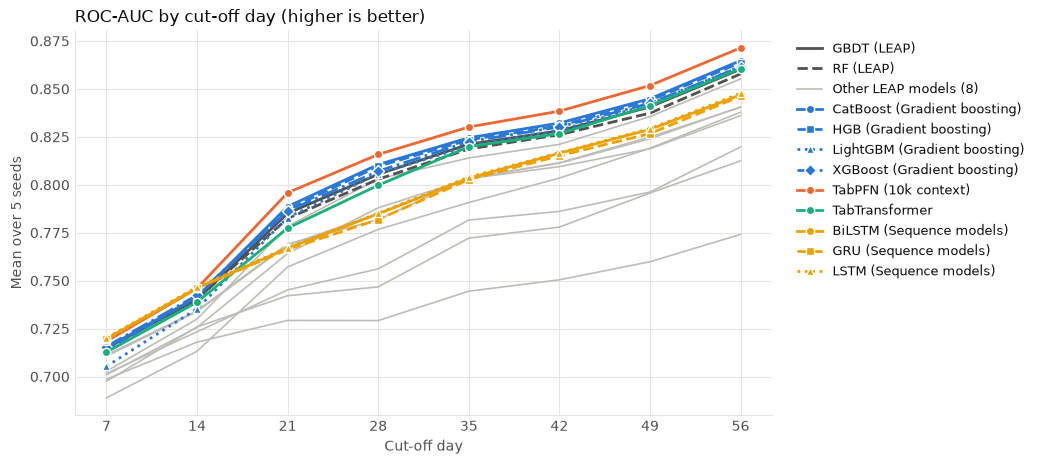

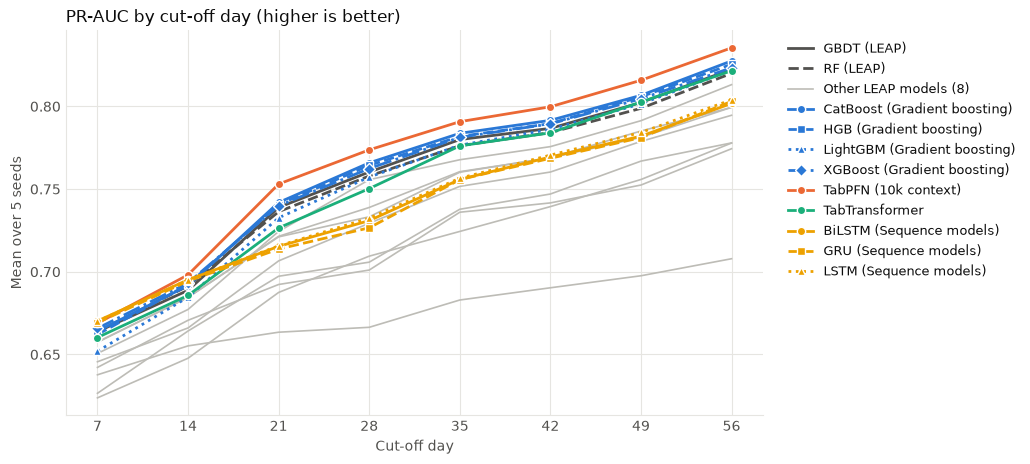

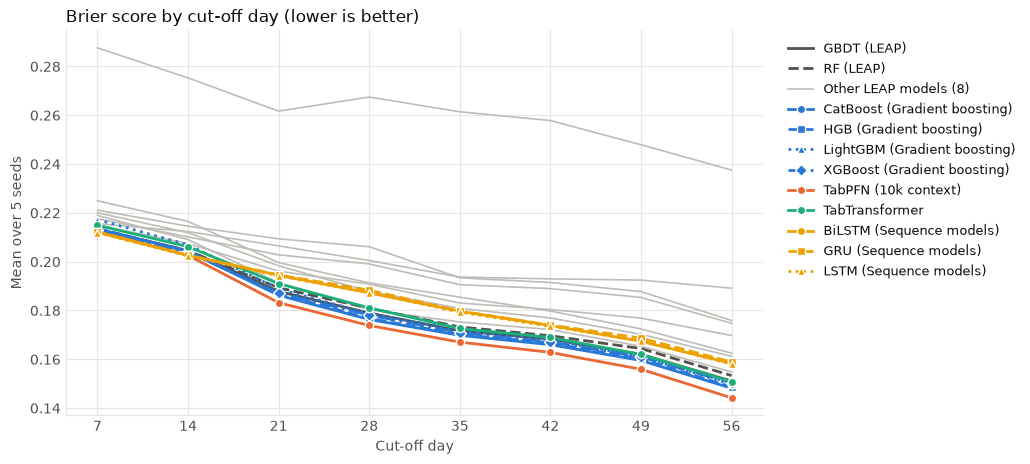

Saved: extension_results/figures/roc_auc_by_day.png, extension_results/figures/pr_auc_by_day.png, extension_results/figures/brier_by_day.png


In [1]:
# 3. Mean over 5 seeds by cut-off day, one chart per metric. Authors' models in grey; new models coloured by
# family (fixed order, one hue per family) and told apart within a family by marker and line style.
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
FAMILY_COLOURS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
STYLES = [("o", "-"), ("s", "--"), ("^", ":"), ("D", "-.")]
INK, MUTED, GRID, LEAP_GREY, SURFACE = "#0b0b0b", "#52514e", "#e6e5e1", "#bdbcb6", "#ffffff"
family_colour = {source: FAMILY_COLOURS[i] for i, source in enumerate(FAMILY_ORDER)}
days = sorted(all_models["t_days"].unique())


def legend_label(model, source):
    name, family = model_label(model), source_label(source)
    return name if family in name else f"{name} ({family})"


def plot_metric(metric, title):
    fig, ax = plt.subplots(figsize=(9, 5), facecolor=SURFACE)
    handles = []
    leap = all_models[all_models["group"] == "LEAP"]
    for model, rows in leap.groupby("model"):
        rows = rows.sort_values("t_days")
        if model in ("gbdt", "rf"):
            ax.plot(rows["t_days"], rows[f"{metric}_mean"], color=MUTED, linewidth=2,
                    linestyle="-" if model == "gbdt" else "--", zorder=2)
        else:
            ax.plot(rows["t_days"], rows[f"{metric}_mean"], color=LEAP_GREY, linewidth=1.2, zorder=1)
    handles += [
        Line2D([], [], color=MUTED, linewidth=2, label="GBDT (LEAP)"),
        Line2D([], [], color=MUTED, linewidth=2, linestyle="--", label="RF (LEAP)"),
        Line2D([], [], color=LEAP_GREY, linewidth=1.2, label=f"Other LEAP models ({leap['model'].nunique() - 2})"),
    ]
    for source in FAMILY_ORDER:
        family = all_models[all_models["source"] == source]
        for (marker, style), model in zip(STYLES, sorted(family["model"].unique())):
            rows = family[family["model"] == model].sort_values("t_days")
            ax.plot(rows["t_days"], rows[f"{metric}_mean"], color=family_colour[source], linewidth=2, linestyle=style,
                    marker=marker, markersize=6, markeredgecolor=SURFACE, markeredgewidth=1, zorder=3,
                    solid_joinstyle="round", solid_capstyle="round")
            handles.append(Line2D([], [], color=family_colour[source], linewidth=2, linestyle=style, marker=marker,
                                  markersize=6, markeredgecolor=SURFACE, label=legend_label(model, source)))
    ax.set_title(title, loc="left", color=INK, fontsize=12)
    ax.set_xlabel("Cut-off day", color=MUTED)
    ax.set_ylabel("Mean over 5 seeds", color=MUTED)
    ax.set_xticks(days)
    ax.tick_params(colors=MUTED, length=0)
    ax.grid(True, color=GRID, linewidth=0.8, linestyle="-")
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)
    ax.set_facecolor(SURFACE)
    legend = ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.02, 1.0), frameon=False, fontsize=9)
    for text in legend.get_texts():
        text.set_color(INK)
    path = FIGURES_DIR / f"{metric}_by_day.png"
    fig.savefig(path, dpi=150, bbox_inches="tight", facecolor=SURFACE)
    plt.show()
    return path


saved = [
    plot_metric("roc_auc", "ROC-AUC by cut-off day (higher is better)"),
    plot_metric("pr_auc", "PR-AUC by cut-off day (higher is better)"),
    plot_metric("brier", "Brier score by cut-off day (lower is better)"),
]
print("Saved:", ", ".join(str(p.relative_to(REPO.parent)) for p in saved))

In [2]:
# 4. Written summary, generated only from the paired table above so it stays true after each refresh.
# "Beat" means higher ROC-AUC than the authors' best model on all 5 paired seeds at that day.
def days_text(day_list):
    day_list = sorted(day_list)
    parts, start = [], day_list[0]
    for previous, current in zip(day_list, day_list[1:] + [None]):
        if current != previous + 7:  # end of a run of consecutive weekly days
            if previous - start > 7:
                parts.append(f"{start} to {previous}")
            else:
                parts += sorted({str(start), str(previous)}, key=int)
            start = current
    return ", ".join(parts[:-1]) + (" and " if len(parts) > 1 else "") + parts[-1]


def span(values):
    low, high = min(values), max(values)
    return f"{low:+.4f}" if round(low, 4) == round(high, 4) else f"{low:+.4f} to {high:+.4f}"


references = reference.groupby("reference", sort=False)["t_days"].apply(list)  # in day order
reference_text = ", ".join(f"{model_label(m)} at days {days_text(d)}" for m, d in references.items())
lines, winners = [], 0
for model in model_order:
    rows = paired[paired["model"] == model].sort_values("t_days")
    wins = rows[rows["roc_auc_better"] == 5]
    brier_wins = rows[rows["brier_better"] == 5]
    name = f"**{model_label(model)}**"
    if len(wins):
        winners += 1
        text = f"- {name} beat it at days {days_text(wins['t_days'].tolist())}, by {span(wins['roc_auc_diff'])} ROC-AUC"
        text += f" and {span(wins['pr_auc_diff'])} PR-AUC on average."
    else:
        text = f"- {name} did not beat it on all 5 seeds at any day. Its mean ROC-AUC difference ranged {span(rows['roc_auc_diff'])}."
    if len(brier_wins):
        text += f" Its Brier score was lower on all 5 seeds at days {days_text(brier_wins['t_days'].tolist())}."
    lines.append(text)

header = (
    f"**{winners} of {len(model_order)} new models beat the authors' best model** ({reference_text}) "
    "on ROC-AUC on all 5 paired seeds at one or more cut-off days."
)
display(Markdown(header + "\n\n" + "\n".join(lines)))

**7 of 9 new models beat the authors' best model** (RF at days 7 and 14, GBDT at days 21 to 56) on ROC-AUC on all 5 paired seeds at one or more cut-off days.

- **CatBoost** beat it at days 21 to 56, by +0.0034 to +0.0051 ROC-AUC and +0.0030 to +0.0055 PR-AUC on average. Its Brier score was lower on all 5 seeds at days 21 to 56.
- **HGB** beat it at days 21 to 56, by +0.0020 to +0.0041 ROC-AUC and +0.0017 to +0.0040 PR-AUC on average. Its Brier score was lower on all 5 seeds at days 14 to 56.
- **LightGBM** did not beat it on all 5 seeds at any day. Its mean ROC-AUC difference ranged -0.0098 to +0.0015.
- **XGBoost** beat it at days 14 to 56, by +0.0012 to +0.0021 ROC-AUC and +0.0009 to +0.0027 PR-AUC on average. Its Brier score was lower on all 5 seeds at days 14 to 56.
- **TabPFN (10k context)** beat it at days 7 to 56, by +0.0033 to +0.0112 ROC-AUC and +0.0050 to +0.0141 PR-AUC on average. Its Brier score was lower on all 5 seeds at days 7 to 56.
- **TabTransformer** did not beat it on all 5 seeds at any day. Its mean ROC-AUC difference ranged -0.0077 to +0.0006.
- **BiLSTM** beat it at days 7 and 14, by +0.0047 to +0.0057 ROC-AUC and +0.0037 to +0.0064 PR-AUC on average. Its Brier score was lower on all 5 seeds at days 7 and 14.
- **GRU** beat it at days 7 and 14, by +0.0043 to +0.0056 ROC-AUC and +0.0029 to +0.0054 PR-AUC on average. Its Brier score was lower on all 5 seeds at days 7 and 14.
- **LSTM** beat it at days 7 and 14, by +0.0051 to +0.0063 ROC-AUC and +0.0037 to +0.0063 PR-AUC on average. Its Brier score was lower on all 5 seeds at days 7 and 14.